# Experiments

Run order: 1) setup, 2) data loading and sanity checks, 3) run an experiment, 4) log and curves, 5) analyses and figures, 6) final test evaluation. The test set is only used in the last section.

In [1]:
# Setup: mount Drive, imports and experiment configuration
from google.colab import drive

drive.mount("/content/drive")

import sys, json, torch

PROJECT_ROOT = "/content/drive/MyDrive/Søren og Magnus/Deep Learning /Project_deep"
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

from src.dataset import build_dataloaders
from src.models import get_resnet18
from src.losses import get_loss_function
from src import sanity_checks as sc
from src.experiment import run_experiment, final_test_eval
from src.experiment_log import summarise

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# Everything that defines an experiment is here. Change ONE factor at a time.
CONFIG = {
    "experiment_id": "E0",  # E0ga = E0g2 protocol plus cosine lr decay
    "seeds": [0, 42, 123],
    "epochs": 10,
    "batch_size": 32,
    "lr": 1e-4,
    "img_size": 224,
    "num_classes": 15,
    "freeze_backbone": False,  # True = train only the new head
    "dropout": 0.0,
    "lr_schedule": "cosine",  # 'constant' (as in E0) or 'cosine' (decays to 0 over the epochs)
}

Mounted at /content/drive
device: cuda


val images 2100, leaf fraction mean 0.38, below 0.05: 11, above 0.95: 3


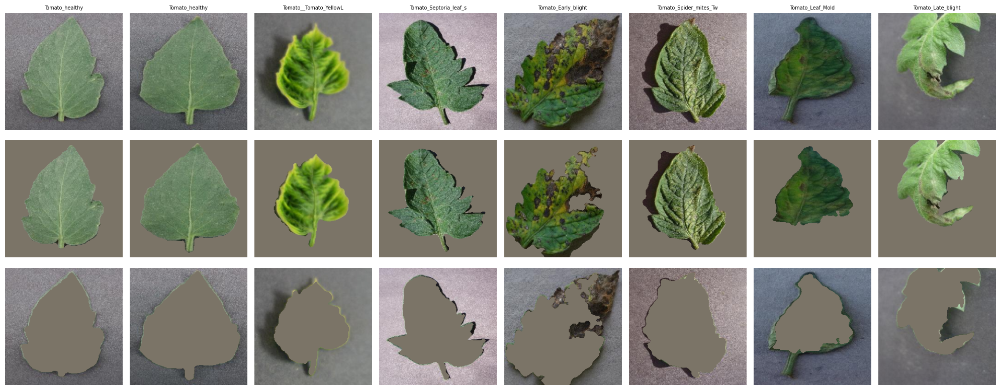


E2: validation, mean ± std over seeds [0, 42, 123] (chance 0.067, majority class 0.153)
condition                      acc        macro-F1   rare-group recall
original           0.9938 ± 0.0005 0.9907 ± 0.0023     0.9662 ± 0.0221
leaf_only          0.6625 ± 0.0045 0.6423 ± 0.0218     0.1304 ± 0.0145
background_only    0.3783 ± 0.0214 0.3075 ± 0.0314     0.0097 ± 0.0167


In [ ]:
# Background test: leaf-only and background-only validation images (set EXP)
import json, numpy as np, torch
from PIL import Image, ImageFilter
from scipy import ndimage as ndi
from skimage.filters import threshold_otsu
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import ImageFolder
import torchvision.transforms as T
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
from src.models import get_resnet18

EXP = "E2"  # change to 'E2' for the second run
SEEDS = [0, 42, 123]
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_tensor = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])


def leaf_mask(img):
    """Boolean leaf mask (224x224) from saturation. Heuristic, check the picture it produces."""
    s = np.asarray(img.convert("HSV"))[..., 1].astype(float)
    s = ndi.gaussian_filter(s, 2)
    m = s > threshold_otsu(s)
    m = ndi.binary_opening(m, iterations=2)
    m = ndi.binary_fill_holes(m)
    lab, n = ndi.label(m)
    if n > 1:
        sizes = ndi.sum(m, lab, range(1, n + 1))
        m = lab == (1 + int(np.argmax(sizes)))
    return m


class ValWithMask(Dataset):
    def __init__(self, root):
        self.ds = ImageFolder(root)
        self.classes = self.ds.classes
        self.rs = T.Resize((224, 224))

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, i):
        img, y = self.ds[i]
        img = self.rs(img.convert("RGB"))
        return to_tensor(img), torch.from_numpy(leaf_mask(img)), y


ds = ValWithMask("/content/data/val")
classes = ds.classes
dl = DataLoader(ds, batch_size=64, shuffle=False, num_workers=2)
X, M, Y = [], [], []
for x, m, y in dl:
    X.append(x.half())
    M.append(m)
    Y.append(y)
X, M, Y = torch.cat(X), torch.cat(M), torch.cat(Y)
frac = M.float().mean(dim=(1, 2)).numpy()
print(
    f"val images {len(Y)}, leaf fraction mean {frac.mean():.2f}, below 0.05: {(frac < 0.05).sum()}, above 0.95: {(frac > 0.95).sum()}"
)

# Picture to check the mask by eye: 8 random images, original / leaf only / background only
rng = np.random.RandomState(0)
pick = rng.choice(len(Y), 8, replace=False)
fig, ax = plt.subplots(3, 8, figsize=(20, 8))
mean_t, std_t = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)


def show(a, t):
    a.imshow((t.float() * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy())
    a.axis("off")


for j, i in enumerate(pick):
    x, m = X[i], M[i]
    show(ax[0, j], x)
    ax[0, j].set_title(classes[Y[i]][:22], fontsize=7)
    show(ax[1, j], x * m)
    show(ax[2, j], x * (~m))
plt.tight_layout()
plt.savefig(f"{PROJECT_ROOT}/runs/background_mask_check.png", dpi=100)
plt.show()

rare = ["Potato___healthy", "Tomato__Tomato_mosaic_virus"]
ri = [classes.index(c) for c in rare]
rows = {}
for cond in ["original", "leaf_only", "background_only"]:
    rows[cond] = []
for seed in SEEDS:
    model = get_resnet18(15, freeze_backbone=False, dropout=0.0).to(device)
    model.load_state_dict(torch.load(f"{PROJECT_ROOT}/checkpoints/{EXP}_seed{seed}.pt", map_location=device))
    model.eval()
    for cond in rows:
        preds = []
        with torch.no_grad():
            for k in range(0, len(Y), 128):
                x = X[k : k + 128].float()
                m = M[k : k + 128].unsqueeze(1)
                if cond == "leaf_only":
                    x = x * m
                if cond == "background_only":
                    x = x * (~m)
                preds.append(model(x.to(device)).argmax(1).cpu())
        p = torch.cat(preds).numpy()
        y = Y.numpy()
        rare_rec = sum((p[y == i] == i).sum() for i in ri) / sum((y == i).sum() for i in ri)
        rows[cond].append(
            {
                "seed": seed,
                "acc": float((p == y).mean()),
                "macro_f1": float(f1_score(y, p, average="macro")),
                "rare_group_recall": float(rare_rec),
            }
        )
print(f"\n{EXP}: validation, mean ± std over seeds {SEEDS} (chance 0.067, majority class 0.153)")
print(f'{"condition":18s}{"acc":>16s}{"macro-F1":>16s}{"rare-group recall":>20s}')
for cond, r in rows.items():
    f = lambda k: f"{np.mean([q[k] for q in r]):.4f} ± {np.std([q[k] for q in r], ddof=1):.4f}"
    print(f'{cond:18s}{f("acc"):>16s}{f("macro_f1"):>16s}{f("rare_group_recall"):>20s}')
json.dump(
    {"exp": EXP, "rows": rows, "leaf_fraction_mean": float(frac.mean())},
    open(f"{PROJECT_ROOT}/runs/background_test_{EXP}.json", "w"),
)

## 1. Data loading and sanity checks

Data ikke fundet lokalt. Udpakker plant_data.zip til /content/data/ ...
Data udpakning færdig!
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 152MB/s]


Focal loss test: CE 3.2320, focal gamma=0 3.2320, focal gamma=2 2.9603. Passed: True
Class weight order test: largest weight is for 'Potato___healthy', smallest class is 'Potato___healthy'. Passed: True
train: mean per channel [-0.122, 0.073, 0.017], std per channel [0.82, 0.731, 0.888], min -2.12, max 2.64
  val: mean per channel [-0.122, 0.075, 0.021], std per channel [0.813, 0.733, 0.887], min -2.12, max 2.64
 test: mean per channel [-0.108, 0.095, 0.027], std per channel [0.806, 0.72, 0.903], min -2.12, max 2.64
A. data statistics sensible: True, splits consistent with each other: True


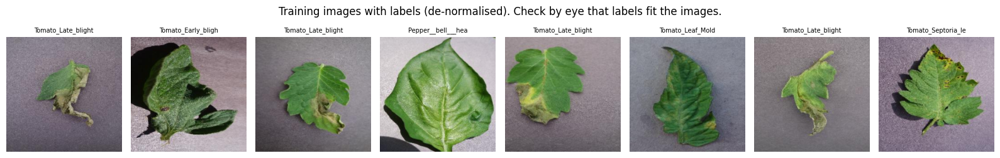

B. identical class lists and order in all splits: True
   overlap train/val: same path 0, same file name 0, same content 0
   overlap train/test: same path 0, same file name 0, same content 0
   overlap val/test: same path 0, same file name 0, same content 0
   split sizes: train 16456 (79.8%), val 2100 (10.2%), test 2077 (10.1%)
   class                                            train     val    test  all
   Pepper__bell___Bacterial_spot                      797     100     100  997
   Pepper__bell___healthy                            1182     148     148  1478
   Potato___Early_blight                              800     100     100  1000
   Potato___Late_blight                               800     100     100  1000
   Potato___healthy                                   120      16      16  152
   Tomato_Bacterial_spot                             1700     215     212  2127
   Tomato_Early_blight                                800     100     100  1000
   Tomato_Late_blight          

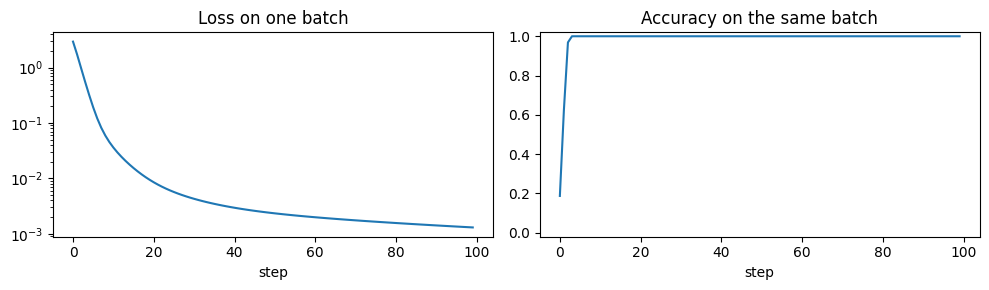


| Check | Result | Pass? |
|---|---|:---:|
| A. Data statistics and images | see output above | yes |
| B. Split overlap and class order | see output above | yes |
| C. Initial loss (3.155 vs ln(C) = 2.708) | see output above | yes |
| D. Overfit one batch (final loss 0.0013, acc 1.00) | see output above | yes |


{'A': True, 'B': True, 'C': True, 'D': True}

In [ ]:
# Data loaders, model and loss, then the sanity checks
train_dir, val_dir, test_dir = "/content/data/train", "/content/data/val", "/content/data/test"
train_loader, val_loader, test_loader, class_names = build_dataloaders(train_dir, val_dir, test_dir, CONFIG)
model = get_resnet18(CONFIG["num_classes"], CONFIG["freeze_backbone"], CONFIG["dropout"]).to(device)
criterion = get_loss_function(CONFIG["experiment_id"], train_loader, device=device)

# Unit-style tests
sc.test_focal_equals_ce()
sc.test_class_weight_order(train_loader, class_names)

# Checks A to D
sc.run_all_checks(
    loaders={"train": train_loader, "val": val_loader, "test": test_loader},
    datasets={"train": train_loader.dataset, "val": val_loader.dataset, "test": test_loader.dataset},
    model=model,
    criterion=criterion,
    device=device,
    class_names=class_names,
)

## BatchNorm diagnosis of the seed 123 collapse

as saved: acc 0.9728 | Tomato_healthy recall 0.732
after BN recalibration: acc 0.9917 | Tomato_healthy recall 0.955
39 healthy images predicted as Target Spot
['06639369-2e38-48cc-a27a-5b90388d227e___RS_HL 0389.JPG', '06d3fe74-beca-4722-ae07-eeb671b82780___RS_HL 9701.JPG', '087e3b12-a80b-435f-8973-a3b07888f8b4___RS_HL 9847.JPG', '0d789240-9714-4378-8b63-4afb12ddfa44___RS_HL 9735.JPG', '12a3a4c8-0f82-419c-9a7f-0fc6d261299a___RS_HL 9988.JPG', '166b90f5-3bba-4aea-9bc4-212efb57a504___RS_HL 0377.JPG', '199f4f32-6e91-4031-b861-bac1abe3452a___RS_HL 9763.JPG', '20d3ba25-f161-4ede-a42a-7a3020ebda3d___RS_HL 0124.JPG', '2a99d5af-218f-4332-a8ce-505301abdbfe___RS_HL 9693.JPG', '2b8306e4-7898-4f27-b659-b0061c4c3832___RS_HL 0440.JPG']


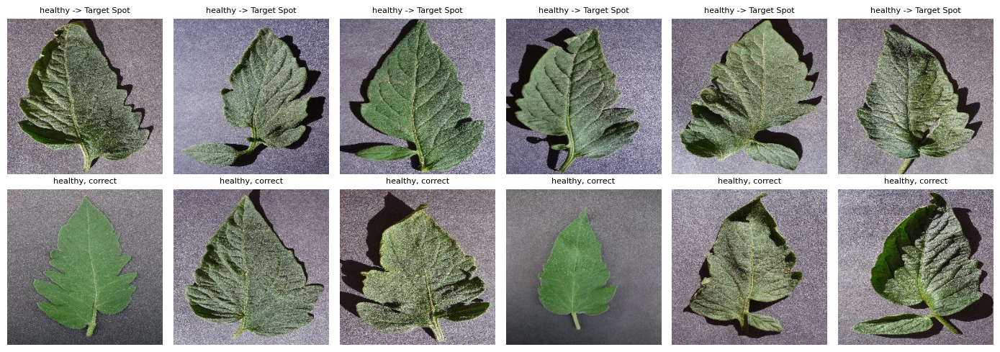

In [ ]:
# Seed 123 collapse: BatchNorm re-estimation and the misclassified images
import copy, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from src.trainer import evaluate_full

ckpt = f"{PROJECT_ROOT}/checkpoints/E0_seed123.pt"
m = get_resnet18(CONFIG["num_classes"], False, 0.0).to(device)
m.load_state_dict(torch.load(ckpt, map_location=device))
base = evaluate_full(m, val_loader, device, class_names=class_names)
print(
    "as saved: acc",
    round(base["accuracy"], 4),
    "| Tomato_healthy recall",
    round(base["class_report"]["Tomato_healthy"]["recall"], 3),
)

# Test 1: re-estimate BatchNorm statistics on train data, weights unchanged
m2 = copy.deepcopy(m)
for mod in m2.modules():
    if isinstance(mod, torch.nn.BatchNorm2d):
        mod.reset_running_stats()
        mod.momentum = None  # cumulative average over the batches below
m2.train()
with torch.no_grad():
    for i, (x, _) in enumerate(train_loader):
        m2(x.to(device))
        if i >= 100:
            break
r2 = evaluate_full(m2, val_loader, device, class_names=class_names)
print(
    "after BN recalibration: acc",
    round(r2["accuracy"], 4),
    "| Tomato_healthy recall",
    round(r2["class_report"]["Tomato_healthy"]["recall"], 3),
)

# Test 2: look at the misclassified images
samples = val_loader.dataset.samples
preds, targets = np.array(base["preds"]), np.array(base["targets"])
h = class_names.index("Tomato_healthy")
t = class_names.index("Tomato__Target_Spot")
wrong = np.where((targets == h) & (preds == t))[0]
right = np.where((targets == h) & (preds == h))[0]
print(len(wrong), "healthy images predicted as Target Spot")
print([Path(samples[i][0]).name for i in wrong[:10]])
fig, ax = plt.subplots(2, 6, figsize=(14, 5))
for a, i in zip(ax[0], wrong[:6]):
    a.imshow(Image.open(samples[i][0]))
    a.set_title("healthy -> Target Spot", fontsize=8)
    a.axis("off")
for a, i in zip(ax[1], right[:6]):
    a.imshow(Image.open(samples[i][0]))
    a.set_title("healthy, correct", fontsize=8)
    a.axis("off")
plt.tight_layout()
plt.show()

## BatchNorm control on all three E0 checkpoints

In [ ]:
from collections import Counter


def recal_bn(model, loader, device, n_batches=100):
    m2 = copy.deepcopy(model)
    for mod in m2.modules():
        if isinstance(mod, torch.nn.BatchNorm2d):
            mod.reset_running_stats()
            mod.momentum = None
    m2.train()
    with torch.no_grad():
        for i, (x, _) in enumerate(loader):
            m2(x.to(device))
            if i >= n_batches:
                break
    return m2


for seed in [0, 42, 123]:
    mm = get_resnet18(CONFIG["num_classes"], False, 0.0).to(device)
    mm.load_state_dict(torch.load(f"{PROJECT_ROOT}/checkpoints/E0_seed{seed}.pt", map_location=device))
    a = evaluate_full(mm, val_loader, device, class_names=class_names)
    b = evaluate_full(recal_bn(mm, train_loader, device), val_loader, device, class_names=class_names)
    print(f'seed {seed}: as saved {a["accuracy"]:.4f} | BN recalibrated {b["accuracy"]:.4f}')


def prefix(i):
    return Path(samples[i][0]).name.split("___", 1)[-1].split(" ")[0]


print("misclassified healthy, by file prefix:", Counter(prefix(i) for i in wrong))
print("correct healthy, by file prefix:      ", Counter(prefix(i) for i in right))

seed 0: as saved 0.9971 | BN recalibrated 0.9976
seed 42: as saved 0.9971 | BN recalibrated 0.9971
seed 123: as saved 0.9728 | BN recalibrated 0.9922
misclassified healthy, by file prefix: Counter({'RS_HL': 38, 'GH_HL': 1})
correct healthy, by file prefix:       Counter({'RS_HL': 58, 'GH_HL': 57})


## Duplicate-image check

In [ ]:
import hashlib, collections
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

DATA = Path("/content/data")
MAX_GROUPS = 12  # how many duplicate groups to display

# 1. Hash every file, remembering which split it came from
by_hash = collections.defaultdict(list)
for split in ["train", "val", "test"]:
    for p in (DATA / split).rglob("*.*"):
        if p.is_file():
            by_hash[hashlib.md5(p.read_bytes()).hexdigest()].append((split, p))

# 2. Keep only hashes that appear in more than one split
cross = {h: v for h, v in by_hash.items() if len({s for s, _ in v}) > 1}

# 3. Summary
n_files = sum(len(v) for v in cross.values())
print(f"{len(cross)} duplicate groups spanning splits ({n_files} files in total)")
pairs = collections.Counter(tuple(sorted({s for s, _ in v})) for v in cross.values())
for combo, n in pairs.items():
    print(f'  {" + ".join(combo)}: {n} groups')

# 4. Show the images: one row per group, one column per copy
groups = list(cross.values())[:MAX_GROUPS]
if groups:
    n_cols = max(len(g) for g in groups)
    fig, axes = plt.subplots(len(groups), n_cols, figsize=(3.2 * n_cols, 3.4 * len(groups)), squeeze=False)
    for row, group in enumerate(groups):
        for col in range(n_cols):
            ax = axes[row, col]
            ax.axis("off")
            if col < len(group):
                split, path = group[col]
                ax.imshow(Image.open(path).convert("RGB"))
                # class folder + filename, split in bold on the first line
                ax.set_title(f"{split.upper()}\n{path.parent.name[:28]}\n{path.name[:28]}", fontsize=8)
    plt.tight_layout()
    plt.show()

0 duplicate groups spanning splits (0 files in total)


In [ ]:
# Leaf key from the file name: val/test images that share it with train
import re, collections


def leaf_key(path):
    return path.split("/")[-1].split("___", 1)[-1].lower()


train_keys = {
    leaf_key(p.relative_to(DATA / "train").as_posix()) for p in (DATA / "train").rglob("*.*") if p.is_file()
}
for split in ["val", "test"]:
    files = [p.relative_to(DATA / split).as_posix() for p in (DATA / split).rglob("*.*") if p.is_file()]
    shared = [f for f in files if leaf_key(f) in train_keys]
    print(split, len(shared), "of", len(files), "share a leaf key with train")

val 4 of 2064 share a leaf key with train
test 1 of 2070 share a leaf key with train


## File-name prefix (capture series) per class in the train set

In [ ]:
# Prefix (capture series) counts per class
import pandas as pd

rows = []
for path, label in train_loader.dataset.samples:
    pre = Path(path).name.split("___", 1)[-1].split(" ")[0]
    rows.append((class_names[label], pre))
df = pd.DataFrame(rows, columns=["class", "prefix"])
print(df.groupby(["class", "prefix"]).size().unstack(fill_value=0).to_string())

prefix                                       2700323949_95aa2eaa01_o.jpg  CG1.JPG  Com.G_SpM_FL  Com.G_TgS_FL  Crnl_L.Mold  GCREC_Bact.Sp  GHLB  GHLB2  GHLB2ES  GHLB_PS  GH_HL  JR_B.Spot  JR_HL  JR_Sept.L.S  Keller.St_CG  Matt.S_CG  NREC_B.Spot  PSU_CG  RS_Early.B  RS_Erly.B  RS_HL  RS_LB  RS_Late.B  Screen  UF.GRC_BS_Lab  UF.GRC_YLCV_Lab  YLCV_GCREC  YLCV_NREC  bell-pepper-plant-61726.jpg
class                                                                                                                                                                                                                                                                                                                                                                                                   
Pepper__bell___Bacterial_spot                                          0        0             0             0            0              0     0      0        0        0      0        462      0            0        

## Leakage check: do val/test images share a leaf id with train images?

In [ ]:
# Leaf id from the file name: val/test images that share a leaf id with train
import re


def leaf_id(name):
    stem = name.split("___", 1)[-1]
    m = re.match(r"(\S+) Leaf (\d+(?:\.\d+)?)", stem)  # e.g. "GHLB_PS Leaf 23.7 Day 13.jpg"
    return (m.group(1), m.group(2)) if m else None


train_ids = {leaf_id(Path(p).name) for p, _ in train_loader.dataset.samples} - {None}
for name, loader in [("val", val_loader), ("test", test_loader)]:
    items = [(Path(p).name, c) for p, c in loader.dataset.samples]
    with_id = [n for n, c in items if leaf_id(n) is not None]
    shared = [n for n in with_id if leaf_id(n) in train_ids]
    print(name, "images with a leaf id:", len(with_id), "| sharing a leaf id with train:", len(shared))

val images with a leaf id: 182 | sharing a leaf id with train: 6
test images with a leaf id: 177 | sharing a leaf id with train: 10


## Leakage check: leaf map from Hugging Face, coverage of our files

In [ ]:
import json, re, urllib.request
from pathlib import Path

url = "https://huggingface.co/datasets/mohanty/PlantVillage/resolve/main/leaf_grouping/leaf-map.json"
leaf_map = json.load(urllib.request.urlopen(url))
print(type(leaf_map), "entries:", len(leaf_map))
for k in list(leaf_map)[:5]:
    print(repr(k), "->", leaf_map[k])


def hf_key(filename):
    name = filename.replace("_final_masked", "")
    if "___" in name:
        name = name.split("___", 1)[-1]
    name = name.split("copy")[0]
    name = re.sub(r"\.(jpg|jpeg|png)$", "", name, flags=re.I)
    return name.lower().strip()


for split, loader in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
    keys = [hf_key(Path(p).name) for p, _ in loader.dataset.samples]
    found = sum(k in leaf_map for k in keys)
    print(split, "files:", len(keys), "| key found in leaf map:", found)

<class 'dict'> entries: 40328
'rutg._hl 3733' -> ['Peach___healthy:::54.0']
'com.g_fl 8310' -> ['Tomato___Target_Spot:::243.0']
'rs_early.b 7557' -> ['Potato___Early_blight:::115.0']
'rs_early.b 7554' -> ['Potato___Early_blight:::115.0']
'uf.citrus_hlb_lab 1658' -> ['Orange___Haunglongbing_(Citrus_greening):::104.0']
train files: 16504 | key found in leaf map: 11923
val files: 2060 | key found in leaf map: 1500
test files: 2069 | key found in leaf map: 1512


## Leakage check: validation/test images that share a leaf group with train

In [ ]:
import collections


def norm(s):
    return re.sub(r"[^a-z0-9]", "", s.lower())


def leaf_group(path, class_name):
    sug = leaf_map.get(hf_key(Path(path).name))
    if not sug:
        return None
    for s in sug:
        cls, _, gid = s.partition(":::")
        if norm(cls) == norm(class_name):
            return s
    return None


groups = {}
for split, loader in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
    groups[split] = [leaf_group(p, class_names[l]) for p, l in loader.dataset.samples]
    print(
        split, "linked to a leaf group:", sum(g is not None for g in groups[split]), "of", len(groups[split])
    )

train_groups = {g for g in groups["train"] if g is not None}
for split, loader in [("val", val_loader), ("test", test_loader)]:
    linked = [
        (g, class_names[l]) for g, (p, l) in zip(groups[split], loader.dataset.samples) if g is not None
    ]
    shared = [(g, c) for g, c in linked if g in train_groups]
    n_all = len(loader.dataset.samples)
    print(
        f"{split}: linked {len(linked)} | sharing a leaf group with train: {len(shared)} "
        f"({len(shared)/len(linked):.1%} of linked, {len(shared)/n_all:.1%} of all)"
    )
    print("  shared by class:", dict(collections.Counter(c for _, c in shared)))

print("\nTrain coverage per class (linked / total):")
cov = collections.defaultdict(lambda: [0, 0])
for g, (p, l) in zip(groups["train"], train_loader.dataset.samples):
    cov[class_names[l]][1] += 1
    if g is not None:
        cov[class_names[l]][0] += 1
for c, (a, b) in cov.items():
    print(f"  {c:45s} {a}/{b}")

train linked to a leaf group: 11923 of 16504
val linked to a leaf group: 1500 of 2060
test linked to a leaf group: 1512 of 2069
val: linked 1500 | sharing a leaf group with train: 1478 (98.5% of linked, 71.7% of all)
  shared by class: {'Pepper__bell___Bacterial_spot': 100, 'Pepper__bell___healthy': 148, 'Potato___Early_blight': 98, 'Potato___Late_blight': 98, 'Potato___healthy': 15, 'Tomato_Bacterial_spot': 213, 'Tomato_Early_blight': 100, 'Tomato_Late_blight': 92, 'Tomato_Leaf_Mold': 95, 'Tomato_Septoria_leaf_spot': 104, 'Tomato_Spider_mites_Two_spotted_spider_mite': 168, 'Tomato__Tomato_YellowLeaf__Curl_Virus': 148, 'Tomato_healthy': 99}
test: linked 1512 | sharing a leaf group with train: 1496 (98.9% of linked, 72.3% of all)
  shared by class: {'Pepper__bell___Bacterial_spot': 100, 'Pepper__bell___healthy': 148, 'Potato___Early_blight': 98, 'Potato___Late_blight': 98, 'Potato___healthy': 16, 'Tomato_Bacterial_spot': 213, 'Tomato_Early_blight': 100, 'Tomato_Late_blight': 101, 'Tomat

## Leaf group sizes and image-number spans

In [ ]:
import pandas as pd

rows = []
for split, loader in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
    for g, (p, l) in zip(groups[split], loader.dataset.samples):
        if g is None:
            continue
        name = Path(p).name.split("___", 1)[-1]
        m = re.search(r"(\d+)\.[A-Za-z]+$", name)
        rows.append((g, split, int(m.group(1)) if m else None, name.split(" ")[0]))
df = pd.DataFrame(rows, columns=["group", "split", "num", "prefix"])

size = df.groupby("group").size()
print(
    "leaf groups:",
    len(size),
    "| images per group: median",
    size.median(),
    "mean",
    round(size.mean(), 1),
    "max",
    size.max(),
)
span = df.dropna().groupby("group")["num"].agg(lambda x: x.max() - x.min())
print(
    "image-number span inside a group: median",
    span.median(),
    "| 90th percentile",
    span.quantile(0.9),
    "| max",
    span.max(),
)
n_splits = df.groupby("group")["split"].nunique()
print("groups spread over 2 or more splits:", int((n_splits > 1).sum()), "of", len(n_splits))

leaf groups: 3717 | images per group: median 4.0 mean 4.0 max 17
image-number span inside a group: median 3.0 | 90th percentile 7.0 | max 7390
groups spread over 2 or more splits: 2125 of 3717


## Leaf-grouped split, step 1: group keys and proxy test (writes nothing)

In [ ]:
# Group keys per image and proxy test for the bucket size
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold

items = []
for split, loader in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
    for g, (p, l) in zip(groups[split], loader.dataset.samples):
        items.append({"path": p, "cls": class_names[l], "split": split, "leafmap": g})
df = pd.DataFrame(items)
df["name"] = df["path"].map(lambda p: Path(p).name.split("___", 1)[-1])
df["prefix"] = df["name"].map(lambda n: n.split(" ")[0])


def get_num(n):
    m = re.search(r"(\d+)\.[A-Za-z]+$", n)
    return int(m.group(1)) if m else -1


df["num"] = df["name"].map(get_num)


def get_leafnum(n):
    m = re.match(r"(\S+) Leaf (\d+(?:\.\d+)?)", n)
    return f"{m.group(1)}|leaf{m.group(2)}" if m else None


df["leafnum"] = df["name"].map(get_leafnum)


def method(r):
    if pd.notna(r["leafmap"]):
        return "leafmap"
    if r["leafnum"] is not None:
        return "leafnum"
    return "proxy"


df["method"] = df.apply(method, axis=1)
print("images per method:", df["method"].value_counts().to_dict())
print(df.groupby(["cls", "method"]).size().unstack(fill_value=0).to_string())


def bucket_key(d, B):
    k = d["cls"] + "|" + d["prefix"] + "|b" + (d["num"] // B).astype(str)
    return k.where(d["num"] >= 0, d["path"])  # unparseable name: image is its own group


def residual_leakage(d, key, seed=0):
    d = d.copy()
    d["k"] = key
    fold = np.full(len(d), -1)
    sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=seed)
    for f, (_, idx) in enumerate(sgkf.split(d, d["cls"], groups=d["k"])):
        fold[idx] = f
    d["fold"] = fold
    return (d.groupby("leafmap")["fold"].nunique() > 1).mean()


lk = df[df["leafmap"].notna()].reset_index(drop=True)
print("\nShare of true leaf groups still cut across folds, linked images only:")
print("  random image split :", f"{residual_leakage(lk, lk['path']):.1%}")
for B in (8, 16, 32, 64):
    k = bucket_key(lk, B)
    print(
        f"  bucket size {B:>3}    :",
        f"{residual_leakage(lk, k):.1%}",
        f"| buckets: {k.nunique()} | median bucket size: {k.value_counts().median():.0f}",
    )

images per method: {'leafmap': 14935, 'proxy': 4126, 'leafnum': 1572}
method                                       leafmap  leafnum  proxy
cls                                                                 
Pepper__bell___Bacterial_spot                    997        0      0
Pepper__bell___healthy                          1476        0      2
Potato___Early_blight                           1000        0      0
Potato___Late_blight                            1000        0      0
Potato___healthy                                 152        0      0
Tomato_Bacterial_spot                           2127        0      0
Tomato_Early_blight                              999        0      1
Tomato_Late_blight                               920      984      2
Tomato_Leaf_Mold                                 952        0      0
Tomato_Septoria_leaf_spot                       1000        0    771
Tomato_Spider_mites_Two_spotted_spider_mite     1676        0      0
Tomato__Target_Spot              

## Leaf-grouped split, step 2: build the split and write splits.json (already run)

In [ ]:
# Build the leaf-grouped split and write splits.json (B=64)
import json, shutil
from src.dataset import MANIFEST_PATH, TRAIN_DIR, VAL_DIR, TEST_DIR

B = 64  # bucket size for images without a leaf group (chosen in step 1)
SEED = 0
DATA = Path("/content/data")
mp = Path(MANIFEST_PATH)
csv_out = mp.with_name("split_groups_v3.csv")
assert not csv_out.exists(), "Grouped split already written. Do not run this cell again."

# 1. Group key per image: leaf map, then leaf number in the name, then the number bucket
bk = bucket_key(df, B)


def pick(i):
    r = df.loc[i]
    if r["method"] == "leafmap":
        return "lm|" + r["leafmap"]
    if r["method"] == "leafnum":
        return r["cls"] + "|ln|" + r["leafnum"]
    return "px|" + bk[i]


df["group"] = [pick(i) for i in df.index]

# 2. Stratified group split: fold 0 = test, fold 1 = val, folds 2 to 9 = train
sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
df["fold"] = -1
for f, (_, idx) in enumerate(sgkf.split(df, df["cls"], groups=df["group"])):
    df.loc[df.index[idx], "fold"] = f
df["new_split"] = np.where(df["fold"] == 0, "test", np.where(df["fold"] == 1, "val", "train"))

# 3. Checks
assert df.groupby("group")["new_split"].nunique().max() == 1, "a group is spread over splits"
print("split sizes:", df["new_split"].value_counts().to_dict())
tab = df.groupby(["cls", "new_split"]).size().unstack(fill_value=0)[["train", "val", "test"]]
tab["all"] = tab.sum(axis=1)
print(tab.to_string())

# 4. Write the new split (the current splits.json is backed up as splits_v2_dedup.json)
df["rel"] = [Path(p).relative_to(DATA / s).as_posix() for p, s in zip(df["path"], df["split"])]
manifest = {s: df.loc[df["new_split"] == s, "rel"].tolist() for s in ["train", "val", "test"]}
backup = mp.with_name("splits_v2_dedup.json")
if not backup.exists():
    shutil.copy(mp, backup)
json.dump(manifest, open(mp, "w"))
df[["rel", "cls", "method", "group", "new_split"]].to_csv(csv_out, index=False)
for d in (TRAIN_DIR, VAL_DIR, TEST_DIR):
    shutil.rmtree(d, ignore_errors=True)
print(
    "New splits.json written, local data folders deleted. Re-run the data loading cell to rebuild the data."
)

split sizes: {'train': 16411, 'test': 2113, 'val': 2109}
new_split                                    train  val  test   all
cls                                                                
Pepper__bell___Bacterial_spot                  750  115   132   997
Pepper__bell___healthy                        1215  144   119  1478
Potato___Early_blight                          792  100   108  1000
Potato___Late_blight                           800  104    96  1000
Potato___healthy                               120   16    16   152
Tomato_Bacterial_spot                         1683  240   204  2127
Tomato_Early_blight                            812   92    96  1000
Tomato_Late_blight                            1529  194   183  1906
Tomato_Leaf_Mold                               776   80    96   952
Tomato_Septoria_leaf_spot                     1514  100   157  1771
Tomato_Spider_mites_Two_spotted_spider_mite   1344  168   164  1676
Tomato__Target_Spot                           1150  254    

## Leaf-grouped split, step 2b: balanced assignment per class (replaces the step 2 result)

In [ ]:
# Balanced assignment per class, write splits.json
from src.dataset import MANIFEST_PATH, TRAIN_DIR, VAL_DIR, TEST_DIR

SEED = 0
targets = {"train": 0.8, "val": 0.1, "test": 0.1}
mp = Path(MANIFEST_PATH)
csv_out = mp.with_name("split_groups_v3.csv")

# 1. Per class: biggest groups first (random order among equal sizes),
#    each group goes to the split that is furthest below its target share
assign = {}
for cls, dc in df.groupby("cls"):
    sizes = dc.groupby("group").size()
    order = sizes.sample(frac=1, random_state=SEED).sort_values(ascending=False, kind="stable")
    n = len(dc)
    cur = {s: 0 for s in targets}
    for g, sz in order.items():
        s = max(targets, key=lambda k: (targets[k] * n - cur[k]) / (targets[k] * n))
        assign[g] = s
        cur[s] += sz
df["new_split"] = df["group"].map(assign)

# 2. Checks
assert df["new_split"].notna().all()
assert df.groupby("group")["new_split"].nunique().max() == 1, "a group is spread over splits"
tab = df.groupby(["cls", "new_split"]).size().unstack(fill_value=0)[["train", "val", "test"]]
tab["all"] = tab.sum(axis=1)
tab["val %"] = (100 * tab["val"] / tab["all"]).round(1)
tab["test %"] = (100 * tab["test"] / tab["all"]).round(1)
print("split sizes:", df["new_split"].value_counts().to_dict())
print(tab.to_string())
assert (tab[["train", "val", "test"]] > 0).all().all(), "a class has an empty split, do NOT continue"

# 3. Write the new split and force the data to be rebuilt
manifest = {s: df.loc[df["new_split"] == s, "rel"].tolist() for s in ["train", "val", "test"]}
json.dump(manifest, open(mp, "w"))
df[["rel", "cls", "method", "group", "new_split"]].to_csv(csv_out, index=False)
for d in (TRAIN_DIR, VAL_DIR, TEST_DIR):
    shutil.rmtree(d, ignore_errors=True)
print("Balanced grouped split written. Re-run the data loading cell to rebuild the data.")

split sizes: {'train': 16398, 'val': 2124, 'test': 2111}
new_split                                    train  val  test   all  val %  test %
cls                                                                               
Pepper__bell___Bacterial_spot                  797  100   100   997   10.0    10.0
Pepper__bell___healthy                        1182  148   148  1478   10.0    10.0
Potato___Early_blight                          800  100   100  1000   10.0    10.0
Potato___Late_blight                           800  100   100  1000   10.0    10.0
Potato___healthy                               120   16    16   152   10.5    10.5
Tomato_Bacterial_spot                         1700  215   212  2127   10.1    10.0
Tomato_Early_blight                            800  100   100  1000   10.0    10.0
Tomato_Late_blight                            1524  191   191  1906   10.0    10.0
Tomato_Leaf_Mold                               760   96    96   952   10.1    10.1
Tomato_Septoria_leaf_spot     

## Leaf-grouped split v4: bucket size 32, balanced assignment (final split)

In [ ]:
# Final split v4: bucket size 32, balanced assignment per class
import os, re, json, shutil
import pandas as pd
from pathlib import Path
from src.dataset import MANIFEST_PATH, TRAIN_DIR, VAL_DIR, TEST_DIR

B_DEFAULT = 32
B_OVERRIDE = {}  # per-class bucket size, e.g. {'Tomato__Tomato_mosaic_virus': 16}
SEED = 0
targets = {"train": 0.8, "val": 0.1, "test": 0.1}

mp = Path(MANIFEST_PATH)
csv_old = mp.with_name("split_groups_v3.csv")
csv_new = mp.with_name("split_groups_v4.csv")
assert not csv_new.exists(), "v4 split already written, do NOT run this cell twice"
shutil.copy(mp, mp.with_name("splits_v3_b64.json"))
shutil.copy(csv_old, mp.with_name("split_groups_v3_b64.csv"))
df = pd.read_csv(csv_old)


def img_num(rel):
    name = os.path.basename(rel).split("___", 1)[-1]
    nums = re.findall(r"\d+", os.path.splitext(name)[0])
    return int(nums[-1]) if nums else None


# 1. New group keys: proxy groups px|class|prefix|b<n> are re-cut with a smaller bucket
is_bucket = (df["method"] == "proxy") & df["group"].str.contains(r"\|b\d+$", regex=True)
nums = df.loc[is_bucket, "rel"].map(img_num)
old_b = df.loc[is_bucket, "group"].str.extract(r"\|b(\d+)$")[0].astype(int)
match = ((nums // 64) == old_b).mean()
print(f"bucket proxy rows: {is_bucket.sum()}, old bucket reproduced from file name for {match:.1%}")
assert match > 0.95, "file-name number parsing does not reproduce the old buckets, do NOT continue"


def new_key(row, num):
    B = B_OVERRIDE.get(row["cls"], B_DEFAULT)
    return re.sub(r"\|b\d+$", f"|B{B}_{int(num) // B}", row["group"])


df.loc[is_bucket, "group"] = [new_key(df.loc[i], n) for i, n in nums.items()]

# 2. Per class: biggest groups first, each to the split furthest below its 80/10/10 target
assign = {}
for cls, dc in df.groupby("cls"):
    sizes = dc.groupby("group").size()
    order = sizes.sample(frac=1, random_state=SEED).sort_values(ascending=False, kind="stable")
    n = len(dc)
    cur = {s: 0 for s in targets}
    for g, sz in order.items():
        s = max(targets, key=lambda k: (targets[k] * n - cur[k]) / (targets[k] * n))
        assign[g] = s
        cur[s] += sz
df["new_split"] = df["group"].map(assign)

# 3. Checks
assert df["new_split"].notna().all()
assert df.groupby("group")["new_split"].nunique().max() == 1, "a group is spread over splits"
tab = df.groupby(["cls", "new_split"]).size().unstack(fill_value=0)[["train", "val", "test"]]
tab["all"] = tab.sum(axis=1)
tab["val %"] = (100 * tab["val"] / tab["all"]).round(1)
tab["test %"] = (100 * tab["test"] / tab["all"]).round(1)
print("split sizes:", df["new_split"].value_counts().to_dict())
print(tab.to_string())
assert (tab[["train", "val", "test"]] > 0).all().all(), "a class has an empty split, do NOT continue"
rows = []
for split in ["val", "test"]:
    d = df[df["new_split"] == split]
    n = d.groupby("cls").size()
    top = d.groupby(["cls", "group"]).size().groupby("cls").max()
    rows += [(split, c, int(n[c]), int(top[c]), round(top[c] / n[c], 3)) for c in n.index]
print(
    pd.DataFrame(rows, columns=["split", "class", "n_images", "largest_group", "share"])
    .sort_values("share", ascending=False)
    .head(8)
    .to_string(index=False)
)

# 4. Write the new split and force the data to be rebuilt
manifest = {s: df.loc[df["new_split"] == s, "rel"].tolist() for s in ["train", "val", "test"]}
json.dump(manifest, open(mp, "w"))
df[["rel", "cls", "method", "group", "new_split"]].to_csv(csv_new, index=False)
for d in (TRAIN_DIR, VAL_DIR, TEST_DIR):
    shutil.rmtree(d, ignore_errors=True)
print("v4 split written. Re-run the data loading cell to rebuild the data.")

bucket proxy rows: 4123, old bucket reproduced from file name for 100.0%
split sizes: {'train': 16456, 'val': 2100, 'test': 2077}
new_split                                    train  val  test   all  val %  test %
cls                                                                               
Pepper__bell___Bacterial_spot                  797  100   100   997   10.0    10.0
Pepper__bell___healthy                        1182  148   148  1478   10.0    10.0
Potato___Early_blight                          800  100   100  1000   10.0    10.0
Potato___Late_blight                           800  100   100  1000   10.0    10.0
Potato___healthy                               120   16    16   152   10.5    10.5
Tomato_Bacterial_spot                         1700  215   212  2127   10.1    10.0
Tomato_Early_blight                            800  100   100  1000   10.0    10.0
Tomato_Late_blight                            1524  191   191  1906   10.0    10.0
Tomato_Leaf_Mold                        

## 2. Run the experiment

Results are saved after every seed to `runs/<experiment>.json` and one row per run is appended to `runs/experiment_log.csv`. Finished seeds are skipped, so it is safe to re-run after a disconnect.

In [ ]:
# Run the experiment defined in CONFIG
saved = run_experiment(CONFIG, PROJECT_ROOT, device, eval_test=False, notes="")

E2: seeds already finished: []

--- running E2 | seed 0 | code version f0ab6407 ---
Epoch 1/10 | lr 1.00e-04 | train loss 0.2858 | val loss 0.0826 | val acc 0.9729 | val F1 0.9712 | 112.2s
Epoch 2/10 | lr 9.76e-05 | train loss 0.0709 | val loss 0.1245 | val acc 0.9624 | val F1 0.9477 | 112.3s
Epoch 3/10 | lr 9.05e-05 | train loss 0.0452 | val loss 0.0390 | val acc 0.9876 | val F1 0.9845 | 113.9s
Epoch 4/10 | lr 7.94e-05 | train loss 0.0340 | val loss 0.0565 | val acc 0.9819 | val F1 0.9780 | 112.6s
Epoch 5/10 | lr 6.55e-05 | train loss 0.0198 | val loss 0.0443 | val acc 0.9814 | val F1 0.9794 | 111.5s
Epoch 6/10 | lr 5.00e-05 | train loss 0.0128 | val loss 0.0285 | val acc 0.9910 | val F1 0.9891 | 111.3s
Epoch 7/10 | lr 3.45e-05 | train loss 0.0083 | val loss 0.0197 | val acc 0.9933 | val F1 0.9933 | 112.2s
Epoch 8/10 | lr 2.06e-05 | train loss 0.0074 | val loss 0.0206 | val acc 0.9924 | val F1 0.9918 | 112.8s
Epoch 9/10 | lr 9.55e-06 | train loss 0.0055 | val loss 0.0196 | val acc 0.9

## 3. Log and curves

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

csv_path = PROJECT_ROOT + "/runs/experiment_log.csv"
print(
    pd.read_csv(csv_path)[
        [
            "date",
            "experiment",
            "seed",
            "code_version",
            "val_acc",
            "val_macro_f1",
            "val_min_class_recall",
            "val_min_recall_class",
            "sec_per_epoch",
        ]
    ].to_string(index=False)
)
print()
print(summarise(csv_path))

            date experiment  seed code_version  val_acc  val_macro_f1  val_min_class_recall          val_min_recall_class  sec_per_epoch
2026-10-06 12:19         E0     0     7b699a0c  0.99709       0.99736               0.97895              Tomato_Leaf_Mold           73.6
2026-10-06 12:31         E0    42     7b699a0c  0.99709       0.99734               0.97857           Tomato__Target_Spot           73.7
2026-10-06 12:43         E0   123     7b699a0c  0.97282       0.97501               0.73248                Tomato_healthy           74.3
2026-10-20 14:26        E0g     0     f0ab6407  0.98540       0.98624               0.88757           Tomato__Target_Spot           65.5
2026-10-20 14:36        E0g    42     f0ab6407  0.98964       0.99016               0.95288            Tomato_Late_blight           65.4
2026-10-20 14:47        E0g   123     f0ab6407  0.98540       0.98448               0.92899           Tomato__Target_Spot           65.0
2026-10-21 06:50       E0g2     0     f0a

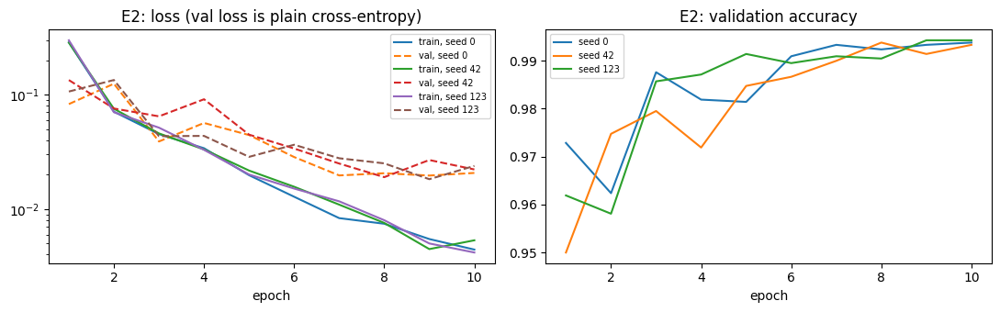

In [ ]:
exp = CONFIG["experiment_id"]
res = json.load(open(f"{PROJECT_ROOT}/runs/{exp}.json"))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for r in res["results"]:
    h = r["history"]
    ep = [x["epoch"] for x in h]
    ax[0].plot(ep, [x["train_loss"] for x in h], "-", label=f"train, seed {r['seed']}")
    ax[0].plot(ep, [x["val_loss"] for x in h], "--", label=f"val, seed {r['seed']}")
    ax[1].plot(ep, [x["val_acc"] for x in h], label=f"seed {r['seed']}")
ax[0].set_title(f"{exp}: loss (val loss is plain cross-entropy)")
ax[0].set_xlabel("epoch")
ax[0].set_yscale("log")
ax[0].legend(fontsize=7)
ax[1].set_title(f"{exp}: validation accuracy")
ax[1].set_xlabel("epoch")
ax[1].legend(fontsize=7)
plt.tight_layout()
plt.savefig(f"{PROJECT_ROOT}/runs/{exp}_curves.png", dpi=120)
plt.show()

                                      class  recall_mean  recall_min
                           Potato___healthy        0.875       0.812
      Tomato__Tomato_YellowLeaf__Curl_Virus        0.980       0.975
                        Tomato_Early_blight        0.987       0.980
                         Tomato_Late_blight        0.991       0.984
                Tomato__Tomato_mosaic_virus        0.994       0.981
                     Pepper__bell___healthy        0.995       0.993
                      Tomato_Bacterial_spot        0.998       0.995
                  Tomato_Septoria_leaf_spot        0.998       0.994
                      Potato___Early_blight        1.000       1.000
              Pepper__bell___Bacterial_spot        1.000       1.000
                       Potato___Late_blight        1.000       1.000
                           Tomato_Leaf_Mold        1.000       1.000
                        Tomato__Target_Spot        1.000       1.000
Tomato_Spider_mites_Two_spotted_sp

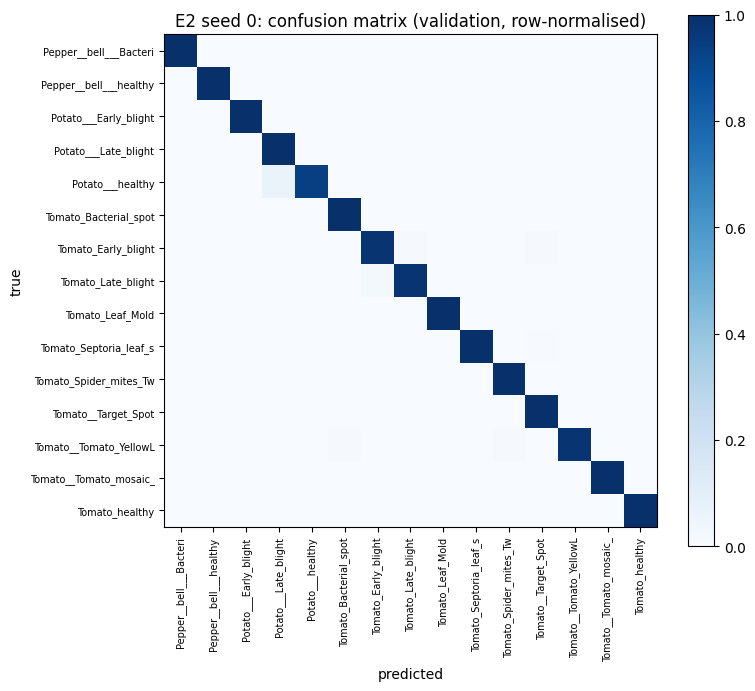

In [ ]:
classes = res["classes"]
recall = np.array([[r["val"]["class_report"][c]["recall"] for c in classes] for r in res["results"]])
print(
    pd.DataFrame(
        {"class": classes, "recall_mean": recall.mean(0).round(3), "recall_min": recall.min(0).round(3)}
    )
    .sort_values("recall_mean")
    .to_string(index=False)
)

seed_idx = 0
cm = np.array(res["results"][seed_idx]["val"]["confusion_matrix"], dtype=float)
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(classes)))
ax.set_yticks(range(len(classes)))
ax.set_xticklabels([c[:22] for c in classes], rotation=90, fontsize=7)
ax.set_yticklabels([c[:22] for c in classes], fontsize=7)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title(f'{exp} seed {res["results"][seed_idx]["seed"]}: confusion matrix (validation, row-normalised)')
plt.colorbar(im)
plt.tight_layout()
plt.savefig(f"{PROJECT_ROOT}/runs/{exp}_confusion.png", dpi=120)
plt.show()

## BatchNorm recalibration on the E0ga checkpoints

In [ ]:
# BatchNorm recalibration on the checkpoints of one experiment (set EXP)
import numpy as np, torch, torch.nn as nn
from src.dataset import build_dataloaders
from src.models import get_resnet18
from src.trainer import evaluate_full
from src.experiment import DEFAULTS

EXP = "E0ga"
cfg = {**DEFAULTS, **CONFIG}
train_loader, val_loader, _, class_names = build_dataloaders(
    "/content/data/train", "/content/data/val", "/content/data/test", cfg
)


def weakest(res):
    cm = np.array(res["confusion_matrix"], dtype=float)
    rec = np.diag(cm) / cm.sum(axis=1)
    i = int(rec.argmin())
    return rec[i], class_names[i]


for seed in cfg["seeds"]:
    model = get_resnet18(
        cfg["num_classes"], freeze_backbone=cfg["freeze_backbone"], dropout=cfg["dropout"]
    ).to(device)
    model.load_state_dict(torch.load(f"{PROJECT_ROOT}/checkpoints/{EXP}_seed{seed}.pt", map_location=device))
    before = evaluate_full(model, val_loader, device, class_names=class_names)
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.reset_running_stats()
            m.momentum = None  # plain average over all batches
    model.train()
    with torch.no_grad():
        for x, _ in train_loader:
            model(x.to(device))
    after = evaluate_full(model, val_loader, device, class_names=class_names)
    wb, nb = weakest(before)
    wa, na = weakest(after)
    print(
        f"seed {seed}: acc {before['accuracy']:.4f} -> {after['accuracy']:.4f} | "
        f"F1 {before['macro_f1']:.4f} -> {after['macro_f1']:.4f} | "
        f"weakest recall {wb:.3f} ({nb}) -> {wa:.3f} ({na})"
    )

seed 0: acc 0.9943 -> 0.9952 | F1 0.9947 -> 0.9955 | weakest recall 0.979 (Tomato_Late_blight) -> 0.981 (Tomato__Tomato_mosaic_virus)
seed 42: acc 0.9971 -> 0.9976 | F1 0.9977 -> 0.9982 | weakest recall 0.986 (Pepper__bell___healthy) -> 0.991 (Tomato__Tomato_YellowLeaf__Curl_Virus)
seed 123: acc 0.9948 -> 0.9957 | F1 0.9908 -> 0.9937 | weakest recall 0.875 (Potato___healthy) -> 0.938 (Potato___healthy)


## Top confusion pairs for E0g, summed over seeds

In [ ]:
# Top confusion pairs for E0g
import json, numpy as np

d = json.load(open(f"{PROJECT_ROOT}/runs/E0g.json"))
classes = d["classes"]
cm = sum(np.array(r["val"]["confusion_matrix"]) for r in d["results"])
pairs = [
    (cm[i, j], classes[i], classes[j])
    for i in range(len(classes))
    for j in range(len(classes))
    if i != j and cm[i, j] > 0
]
for n, t, p in sorted(pairs, reverse=True)[:10]:
    print(f"{int(n):3d} images (3 seeds summed): true {t} -> predicted {p}")

 36 images (3 seeds summed): true Tomato__Target_Spot -> predicted Tomato_Spider_mites_Two_spotted_spider_mite
  9 images (3 seeds summed): true Tomato_Late_blight -> predicted Tomato_Early_blight
  5 images (3 seeds summed): true Tomato_Early_blight -> predicted Tomato_Late_blight
  4 images (3 seeds summed): true Tomato_Septoria_leaf_spot -> predicted Tomato_Late_blight
  4 images (3 seeds summed): true Potato___Early_blight -> predicted Pepper__bell___Bacterial_spot
  3 images (3 seeds summed): true Tomato__Tomato_mosaic_virus -> predicted Tomato_Spider_mites_Two_spotted_spider_mite
  3 images (3 seeds summed): true Tomato_Septoria_leaf_spot -> predicted Tomato_Leaf_Mold
  3 images (3 seeds summed): true Pepper__bell___healthy -> predicted Tomato_Late_blight
  2 images (3 seeds summed): true Tomato_healthy -> predicted Tomato__Tomato_mosaic_virus
  2 images (3 seeds summed): true Tomato_Late_blight -> predicted Tomato_healthy


## Misclassified Target Spot images (E0g, seed 0)

19 misclassified Target Spot images


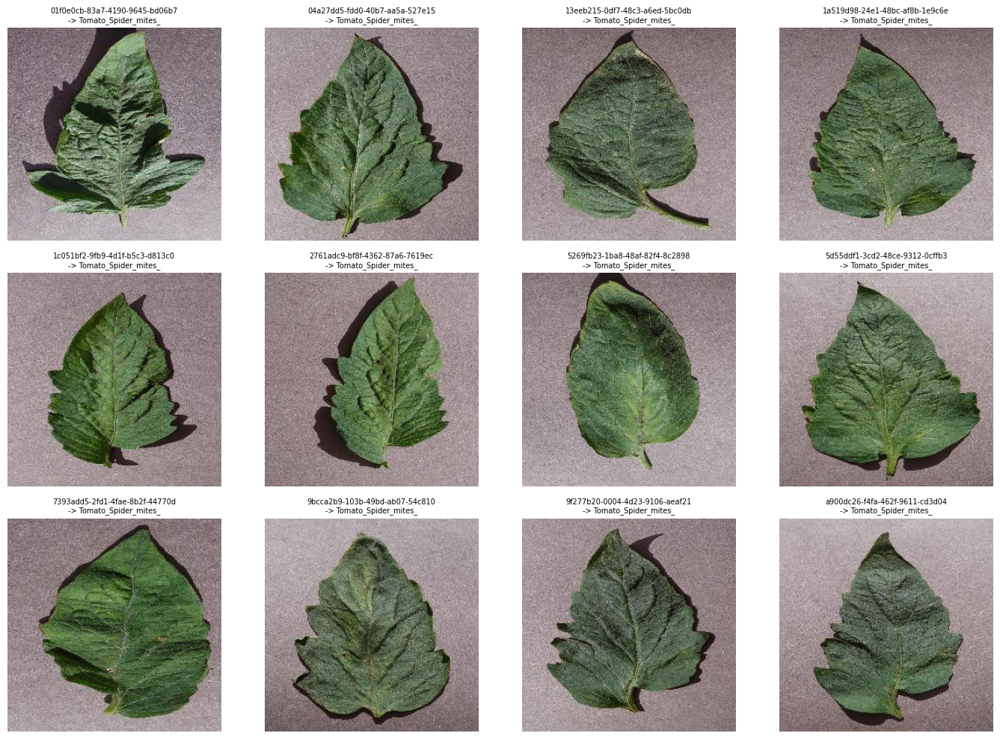

In [ ]:
import torch, matplotlib.pyplot as plt
from PIL import Image
from src.dataset import build_dataloaders
from src.models import get_resnet18
from src.trainer import evaluate_full
from src.experiment import DEFAULTS

cfg = {**DEFAULTS, **CONFIG}
_, val_loader, _, class_names = build_dataloaders(
    "/content/data/train", "/content/data/val", "/content/data/test", cfg
)
model = get_resnet18(cfg["num_classes"], freeze_backbone=cfg["freeze_backbone"], dropout=cfg["dropout"]).to(
    device
)
model.load_state_dict(torch.load(f"{PROJECT_ROOT}/checkpoints/E0g_seed0.pt", map_location=device))
res = evaluate_full(model, val_loader, device, class_names=class_names)

paths = [p for p, _ in val_loader.dataset.samples]  # assumes an ImageFolder dataset, same order as preds
t = class_names.index("Tomato__Target_Spot")
wrong = [i for i, (y, p) in enumerate(zip(res["targets"], res["preds"])) if y == t and p != t]
print(len(wrong), "misclassified Target Spot images")
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, i in zip(axes.ravel(), wrong[:12]):
    ax.imshow(Image.open(paths[i]))
    ax.axis("off")
    ax.set_title(f"{paths[i].split('/')[-1][:30]}\n-> {class_names[res['preds'][i]][:20]}", fontsize=7)
plt.tight_layout()
plt.show()

In [ ]:
# File name tails of the misclassified Target Spot images
for i in wrong:
    print(paths[i].split("/")[-1][-26:], "->", class_names[res["preds"][i]][:22])

65___Com.G_TgS_FL 8318.JPG -> Tomato_Spider_mites_Tw
99___Com.G_TgS_FL 9679.JPG -> Tomato_Spider_mites_Tw
5f___Com.G_TgS_FL 9723.JPG -> Tomato_Spider_mites_Tw
e8___Com.G_TgS_FL 9678.JPG -> Tomato_Spider_mites_Tw
ca___Com.G_TgS_FL 9683.JPG -> Tomato_Spider_mites_Tw
be___Com.G_TgS_FL 9681.JPG -> Tomato_Spider_mites_Tw
ec___Com.G_TgS_FL 9694.JPG -> Tomato_Spider_mites_Tw
3f___Com.G_TgS_FL 9676.JPG -> Tomato_Spider_mites_Tw
69___Com.G_TgS_FL 9719.JPG -> Tomato_Spider_mites_Tw
32___Com.G_TgS_FL 9684.JPG -> Tomato_Spider_mites_Tw
ad___Com.G_TgS_FL 9671.JPG -> Tomato_Spider_mites_Tw
4e___Com.G_TgS_FL 9668.JPG -> Tomato_Spider_mites_Tw
36___Com.G_TgS_FL 1109.JPG -> Tomato_Spider_mites_Tw
7e___Com.G_TgS_FL 9687.JPG -> Tomato_Spider_mites_Tw
5d___Com.G_TgS_FL 9702.JPG -> Tomato_Spider_mites_Tw
52___Com.G_TgS_FL 9677.JPG -> Tomato_Spider_mites_Tw
04___Com.G_TgS_FL 9680.JPG -> Tomato_Spider_mites_Tw
50___Com.G_TgS_FL 9720.JPG -> Tomato_Spider_mites_Tw
01___Com.G_TgS_FL 9682.JPG -> Tomato_Spider_mi

In [ ]:
# Target Spot capture series: images with numbers 9664 to 9727 per split
import re, os, glob

pat = re.compile(r"Com\.G_TgS_FL (\d+)")
lo, hi = 9664, 9727
for split in ["train", "val", "test"]:
    files = glob.glob(f"/content/data/{split}/Tomato__Target_Spot/*")
    nums = [int(m.group(1)) for f in files if (m := pat.search(os.path.basename(f)))]
    print(
        f"{split}: {len(files)} Target Spot images, {len(nums)} with prefix Com.G_TgS_FL, "
        f"{sum(lo <= n <= hi for n in nums)} with number in {lo}-{hi}"
    )
wrong_in = sum(
    1 for i in wrong if (m := pat.search(os.path.basename(paths[i]))) and lo <= int(m.group(1)) <= hi
)
print(f"seed 0 val errors inside the range: {wrong_in} of {len(wrong)}")

train: 1077 Target Spot images, 1077 with prefix Com.G_TgS_FL, 0 with number in 9664-9727
val: 169 Target Spot images, 169 with prefix Com.G_TgS_FL, 63 with number in 9664-9727
test: 158 Target Spot images, 158 with prefix Com.G_TgS_FL, 0 with number in 9664-9727
seed 0 val errors inside the range: 17 of 19


In [ ]:
# Largest group share per class in val and test
import pandas as pd

df = pd.read_csv(f"{PROJECT_ROOT}/split_groups_v3.csv")
print(df.columns.tolist())  # expected: rel, cls, method, group, new_split
rows = []
for split in ["val", "test"]:
    d = df[df["new_split"] == split]
    n = d.groupby("cls").size()
    top = d.groupby(["cls", "group"]).size().groupby("cls").max()
    for c in n.index:
        rows.append((split, c, int(n[c]), int(top[c]), round(top[c] / n[c], 3)))
out = pd.DataFrame(rows, columns=["split", "class", "n_images", "largest_group", "share"])
print(out.sort_values("share", ascending=False).head(12).to_string(index=False))

['rel', 'cls', 'method', 'group', 'new_split']
split                                 class  n_images  largest_group  share
  val           Tomato__Tomato_mosaic_virus        64             64  1.000
 test           Tomato__Tomato_mosaic_virus        64             64  1.000
 test                   Tomato__Target_Spot       158             64  0.405
  val                   Tomato__Target_Spot       169             64  0.379
  val             Tomato_Septoria_leaf_spot       177             64  0.362
 test             Tomato_Septoria_leaf_spot       178             64  0.360
 test                      Potato___healthy        16              4  0.250
  val                      Potato___healthy        16              4  0.250
  val         Pepper__bell___Bacterial_spot       100             17  0.170
 test         Pepper__bell___Bacterial_spot       100             16  0.160
  val Tomato__Tomato_YellowLeaf__Curl_Virus       321             44  0.137
 test Tomato__Tomato_YellowLeaf__Curl_Vir

In [ ]:
# Group labels in split_groups_v3.csv
print(df["method"].value_counts())
print(df.groupby("method").head(3).sort_values("method").to_string(index=False))

method
leafmap    14935
proxy       4126
leafnum     1572
Name: count, dtype: int64
                                                                                                   rel                           cls  method                                                                                                                         group new_split
               Pepper__bell___Bacterial_spot/0022d6b7-d47c-4ee2-ae9a-392a53f48647___JR_B.Spot 8964.JPG Pepper__bell___Bacterial_spot leafmap                                                                                    lm|Pepper,_bell___Bacterial_spot:::JR_51.0     train
               Pepper__bell___Bacterial_spot/006adb74-934f-448f-a14f-62181742127b___JR_B.Spot 3395.JPG Pepper__bell___Bacterial_spot leafmap                                                                                    lm|Pepper,_bell___Bacterial_spot:::JR_27.0       val
               Pepper__bell___Bacterial_spot/00f2e69a-1e56-412d-8a79-fdce794a17e4___J

In [ ]:
# Leakage by bucket size B, measured on leaf-map groups
import os, re
import pandas as pd

df = pd.read_csv(f"{PROJECT_ROOT}/split_groups_v3.csv")


def img_num(rel):
    name = os.path.basename(rel).split("___", 1)[-1]
    nums = re.findall(r"\d+", os.path.splitext(name)[0])
    return int(nums[-1]) if nums else None


lm = df[df["method"] == "leafmap"].copy()
lm["num"] = lm["rel"].map(img_num)
lm = lm.dropna(subset=["num"])
multi = lm.groupby("group").filter(lambda g: len(g) > 1)
n_groups = multi["group"].nunique()
rows = []
for B in [8, 16, 32, 64]:
    cut = multi.groupby("group")["num"].apply(lambda s: (s // B).nunique() > 1)
    cut_imgs = multi[multi["group"].isin(cut[cut].index)].shape[0]
    rows.append((B, int(cut.sum()), round(cut.mean(), 3), round(cut_imgs / len(multi), 3)))
print(f"leaf-map groups with 2 or more images: {n_groups} ({len(multi)} images)")
print(
    pd.DataFrame(
        rows, columns=["B", "groups_cut", "share_groups_cut", "share_images_in_cut_groups"]
    ).to_string(index=False)
)

leaf-map groups with 2 or more images: 3612 (14830 images)
 B  groups_cut  share_groups_cut  share_images_in_cut_groups
 8        1831             0.507                       0.551
16         951             0.263                       0.294
32         474             0.131                       0.148
64         249             0.069                       0.078


In [ ]:
# Per-class correct/total for E0ga, E1a and E1b (per seed for the rare classes, pooled for all)
import json, numpy as np

exps = ["E0ga", "E1a", "E1b"]
rare = ["Potato___healthy", "Tomato__Tomato_mosaic_virus"]
data = {e: json.load(open(f"{PROJECT_ROOT}/runs/{e}.json")) for e in exps}
classes = data[exps[0]]["classes"]


def counts(e):
    out = []
    for r in data[e]["results"]:
        cm = np.array(r["val"]["confusion_matrix"])
        out.append((r["seed"], np.diag(cm), cm.sum(axis=1)))
    return out


print("Per seed, correct / total:")
for c in rare:
    i = classes.index(c)
    for e in exps:
        print(f"{c:30s} {e:5s} " + "  ".join(f"seed {s}: {d[i]}/{t[i]}" for s, d, t in counts(e)))

print("\nPooled over the seeds, correct / total (recall):")
print(f"{'class':45s}" + "".join(f"{e:>18s}" for e in exps))
for i, c in enumerate(classes):
    row = ""
    for e in exps:
        d = sum(x[1][i] for x in counts(e))
        t = sum(x[2][i] for x in counts(e))
        row += f"{(str(d) + '/' + str(t) + ' (' + format(d / t, '.3f') + ')'):>18s}"
    print(f"{c:45s}{row}")

Per seed, correct / total:
Potato___healthy               E0ga  seed 0: 16/16  seed 42: 16/16  seed 123: 14/16
Potato___healthy               E1a   seed 0: 16/16  seed 42: 16/16  seed 123: 16/16
Potato___healthy               E1b   seed 0: 16/16  seed 42: 15/16  seed 123: 16/16
Tomato__Tomato_mosaic_virus    E0ga  seed 0: 52/53  seed 42: 53/53  seed 123: 52/53
Tomato__Tomato_mosaic_virus    E1a   seed 0: 52/53  seed 42: 53/53  seed 123: 52/53
Tomato__Tomato_mosaic_virus    E1b   seed 0: 52/53  seed 42: 51/53  seed 123: 52/53

Pooled over the seeds, correct / total (recall):
class                                                      E0ga               E1a               E1b
Pepper__bell___Bacterial_spot                   300/300 (1.000)   300/300 (1.000)   298/300 (0.993)
Pepper__bell___healthy                          441/444 (0.993)   441/444 (0.993)   441/444 (0.993)
Potato___Early_blight                           300/300 (1.000)   300/300 (1.000)   300/300 (1.000)
Potato___Late_bligh

In [ ]:
# Pooled recall and precision per class for E0ga, E1a, E1b and E1c
import json, numpy as np

exps = ["E0ga", "E1a", "E1b", "E1c"]
rare = ["Potato___healthy", "Tomato__Tomato_mosaic_virus"]
data = {e: json.load(open(f"{PROJECT_ROOT}/runs/{e}.json")) for e in exps}
classes = data[exps[0]]["classes"]
for e in exps:
    print(f"\n{e}:")
    runs = data[e]["results"]
    cm = sum(np.array(r["val"]["confusion_matrix"]) for r in runs)
    print(f"{e}: pooled over {len(runs)} seeds")
    print(f'{"class":40s} {"correct/total":>14s} {"recall":>7s} {"precision":>9s}')
    for i, c in enumerate(classes):
        tot, cor, pred = cm[i].sum(), cm[i, i], cm[:, i].sum()
        mark = "  <- rare" if c in rare else ""
        print(f"{c:40s} {cor:>6d}/{tot:<7d} {cor/tot:7.3f} {cor/max(pred,1):9.3f}{mark}")

Top-level keys in E1c.json: ['config', 'results', 'classes']

E0ga:
  per-seed results found under key "results" (list)
E0ga: pooled over 3 seeds
class                                     correct/total  recall precision
Pepper__bell___Bacterial_spot               300/300       1.000     1.000
Pepper__bell___healthy                      441/444       0.993     1.000
Potato___Early_blight                       300/300       1.000     1.000
Potato___Late_blight                        300/300       1.000     0.990
Potato___healthy                             46/48        0.958     1.000  <- rare
Tomato_Bacterial_spot                       645/645       1.000     0.995
Tomato_Early_blight                         297/300       0.990     0.980
Tomato_Late_blight                          566/573       0.988     0.991
Tomato_Leaf_Mold                            288/288       1.000     1.000
Tomato_Septoria_leaf_spot                   534/534       1.000     0.993
Tomato_Spider_mites_Two_spotted

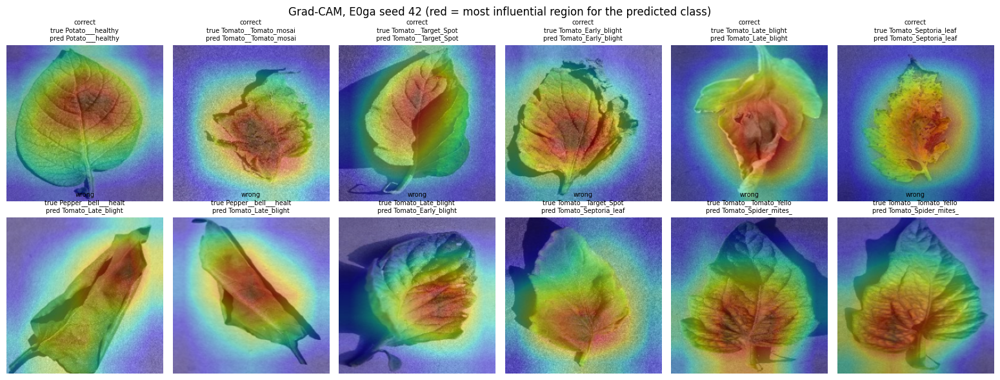

saved /content/drive/MyDrive/Søren og Magnus/Deep Learning /Project_deep/runs/E0ga_gradcam_seed42.png


In [ ]:
# Grad-CAM for one checkpoint (saves a PNG to the project folder)
import numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from src.dataset import build_dataloaders
from src.models import get_resnet18
from src.trainer import evaluate_full
from src.experiment import DEFAULTS

EXP, SEED = "E0ga", 42  # which checkpoint to explain: checkpoints/<EXP>_seed<SEED>.pt
SHOW_CLASSES = [
    "Potato___healthy",
    "Tomato__Tomato_mosaic_virus",
    "Tomato__Target_Spot",
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Tomato_Septoria_leaf_spot",
]
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def grad_cam(model, target_layer, x, class_idx=None):
    """Lecturer's Grad-CAM function (Lab 6 template). Returns heatmaps in [0, 1] and the explained class indices."""
    store = {}

    def forward_hook(module, inp, out):
        store["act"] = out
        out.register_hook(lambda grad: store.__setitem__("grad", grad))

    handle = target_layer.register_forward_hook(forward_hook)
    model.eval()
    with torch.enable_grad():
        logits = model(x)
        if class_idx is None:
            class_idx = logits.argmax(1)
        model.zero_grad()
        logits.gather(1, class_idx.view(-1, 1)).sum().backward()
    handle.remove()
    weights = store["grad"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * store["act"]).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
    cam = cam / (cam.amax(dim=(2, 3), keepdim=True) + 1e-8)
    return cam.squeeze(1).detach().cpu(), class_idx.cpu()


cfg = {**DEFAULTS, **CONFIG}
_, val_loader, _, class_names = build_dataloaders(
    "/content/data/train", "/content/data/val", "/content/data/test", cfg
)
model = get_resnet18(cfg["num_classes"], freeze_backbone=cfg["freeze_backbone"], dropout=cfg["dropout"]).to(
    device
)
model.load_state_dict(torch.load(f"{PROJECT_ROOT}/checkpoints/{EXP}_seed{SEED}.pt", map_location=device))
model.eval()

# Images shown: first correct image per class in SHOW_CLASSES, first 6 misclassified images
res = evaluate_full(model, val_loader, device, class_names=class_names)
preds, targets = np.array(res["preds"]), np.array(res["targets"])
correct = []
for c in SHOW_CLASSES:
    ci = class_names.index(c)
    idx = np.where((targets == ci) & (preds == ci))[0]
    if len(idx):
        correct.append(int(idx[0]))
wrong = [int(i) for i in np.where(preds != targets)[0][:6]]
rows = [("correct", correct), ("wrong", wrong)]
ncol = max(len(correct), len(wrong))

fig, axes = plt.subplots(2, ncol, figsize=(2.6 * ncol, 6))
for r, (label, idxs) in enumerate(rows):
    for col in range(ncol):
        ax = axes[r, col]
        ax.axis("off")
        if col >= len(idxs):
            continue
        i = idxs[col]
        x, y = val_loader.dataset[i]  # image after the eval transform
        cam, cls = grad_cam(model, model.layer4, x.unsqueeze(0).to(device))
        img = (x * STD + MEAN).clamp(0, 1)
        ax.imshow(img.permute(1, 2, 0).numpy())
        ax.imshow(cam[0].numpy(), cmap="jet", alpha=0.4)
        ax.set_title(f"{label}\ntrue {class_names[y][:20]}\npred {class_names[cls.item()][:20]}", fontsize=7)
plt.suptitle(f"Grad-CAM, {EXP} seed {SEED} (red = most influential region for the predicted class)")
plt.tight_layout()
out = f"{PROJECT_ROOT}/runs/{EXP}_gradcam_seed{SEED}.png"
plt.savefig(out, dpi=150)
plt.show()
print("saved", out)

## Fraction splits

In [ ]:
# Reduced training sets (symlinks) at 25, 10, 5 and 2 percent of the training set
import os, shutil
import numpy as np
from pathlib import Path

SRC = Path("/content/data")
OUT = Path("/content/data_frac")  # derived folders only, splits.json and /content/data are never changed
FRACTIONS = {"f25": 0.25, "f10": 0.10, "f05": 0.05, "f02": 0.02}
SUBSET_SEED = 2026  # fixed: every experiment and every training seed uses the same images
MIN_PER_CLASS = 2

classes = sorted(p.name for p in (SRC / "train").iterdir() if p.is_dir())
assert len(classes) == 15, classes
files = {c: sorted(f for f in os.listdir(SRC / "train" / c)) for c in classes}

rng = np.random.RandomState(SUBSET_SEED)
order = {
    c: rng.permutation(len(files[c])) for c in classes
}  # one permutation per class, so the subsets are nested

# Safety check: no chosen train image may also be in val or test (same class and file name)
held_out = {(c, f) for sp in ("val", "test") for c in classes for f in os.listdir(SRC / sp / c)}

if OUT.exists():
    shutil.rmtree(OUT)

print(
    f'{"fraction":9s} {"train imgs":>10s} {"min class":>10s} {"Potato healthy":>15s} {"Tomato mosaic":>14s}'
)
for tag, frac in FRACTIONS.items():
    total = 0
    counts = {}
    for c in classes:
        k = max(MIN_PER_CLASS, int(round(frac * len(files[c]))))
        chosen = [files[c][i] for i in order[c][:k]]
        assert not any((c, f) in held_out for f in chosen), "overlap with val or test"
        d = OUT / tag / "train" / c
        d.mkdir(parents=True, exist_ok=True)
        for f in chosen:
            os.symlink((SRC / "train" / c / f).resolve(), d / f)
        counts[c] = len(chosen)
        total += len(chosen)
    print(
        f"{tag:9s} {total:>10d} {min(counts.values()):>10d} "
        f'{counts["Potato___healthy"]:>15d} {counts["Tomato__Tomato_mosaic_virus"]:>14d}'
    )

fraction  train imgs  min class  Potato healthy  Tomato mosaic
f25             4116         30              30             72
f10             1646         12              12             29
f05              823          6               6             14
f02              328          2               2              6


In [ ]:
# Baseline (cosine lr) trained on 25, 10, 5 and 2 percent
FRAC_RUNS = [("E0f25", "f25"), ("E0f10", "f10"), ("E0f05", "f05"), ("E0f02", "f02")]
for exp_id, tag in FRAC_RUNS:
    n_train = sum(len(os.listdir(OUT / tag / "train" / c)) for c in classes)
    cfg = {**CONFIG, "experiment_id": exp_id, "lr_schedule": "cosine"}
    run_experiment(
        cfg,
        PROJECT_ROOT,
        device,
        eval_test=False,
        notes=f"data fraction {tag}, {n_train} train images",
        train_dir=str(OUT / tag / "train"),
    )

E0f25: seeds already finished: []

--- running E0f25 | seed 0 | code version f0ab6407 ---
Epoch 1/10 | lr 1.00e-04 | train loss 0.6061 | val loss 0.1644 | val acc 0.9505 | val F1 0.9367 | 20.5s
Epoch 2/10 | lr 9.76e-05 | train loss 0.1046 | val loss 0.0809 | val acc 0.9771 | val F1 0.9686 | 21.6s
Epoch 3/10 | lr 9.05e-05 | train loss 0.0480 | val loss 0.0789 | val acc 0.9733 | val F1 0.9649 | 20.9s
Epoch 4/10 | lr 7.94e-05 | train loss 0.0289 | val loss 0.0715 | val acc 0.9738 | val F1 0.9653 | 20.6s
Epoch 5/10 | lr 6.55e-05 | train loss 0.0175 | val loss 0.0750 | val acc 0.9748 | val F1 0.9719 | 20.6s
Epoch 6/10 | lr 5.00e-05 | train loss 0.0120 | val loss 0.0576 | val acc 0.9810 | val F1 0.9767 | 20.7s
Epoch 7/10 | lr 3.45e-05 | train loss 0.0092 | val loss 0.0644 | val acc 0.9795 | val F1 0.9768 | 20.9s
Epoch 8/10 | lr 2.06e-05 | train loss 0.0087 | val loss 0.0582 | val acc 0.9824 | val F1 0.9801 | 20.6s
Epoch 9/10 | lr 9.55e-06 | train loss 0.0060 | val loss 0.0606 | val acc 0.980

In [ ]:
# Pooled recall per class for E0ga and the four data fractions
import json, numpy as np

exps = ["E0ga", "E0f25", "E0f10", "E0f05", "E0f02"]
rare = ["Potato___healthy", "Tomato__Tomato_mosaic_virus"]
data = {e: json.load(open(f"{PROJECT_ROOT}/runs/{e}.json")) for e in exps}
classes = data["E0ga"]["classes"]
assert all(data[e]["classes"] == classes for e in exps), "class order differs"
cms = {e: sum(np.array(r["val"]["confusion_matrix"]) for r in data[e]["results"]) for e in exps}

print("Pooled recall over 3 seeds (correct/total in brackets for the rare classes)")
print(f'{"class (val imgs per seed)":48s}' + "".join(f"{e:>9s}" for e in exps))
for i, c in enumerate(classes):
    n = cms["E0ga"][i].sum() // 3
    row = "".join(f"{cms[e][i, i] / cms[e][i].sum():9.3f}" for e in exps)
    print(f'{c + " (" + str(n) + ")":48s}{row}' + ("  <- rare" if c in rare else ""))

print("\nRare classes: correct/total and precision")
for c in rare:
    i = classes.index(c)
    for e in exps:
        cm = cms[e]
        print(
            f"{c:32s} {e:6s} {cm[i, i]:>4d}/{cm[i].sum():<4d} recall {cm[i, i] / cm[i].sum():.3f}  precision {cm[i, i] / max(cm[:, i].sum(), 1):.3f}"
        )

Pooled recall over 3 seeds (correct/total in brackets for the rare classes)
class (val imgs per seed)                            E0ga    E0f25    E0f10    E0f05    E0f02
Pepper__bell___Bacterial_spot (100)                 1.000    0.980    0.983    0.977    0.910
Pepper__bell___healthy (148)                        0.993    0.995    0.998    0.998    0.998
Potato___Early_blight (100)                         1.000    1.000    1.000    0.987    0.967
Potato___Late_blight (100)                          1.000    0.993    0.980    0.893    0.830
Potato___healthy (16)                               0.958    0.917    0.958    0.854    0.229  <- rare
Tomato_Bacterial_spot (215)                         1.000    0.998    0.995    0.991    0.885
Tomato_Early_blight (100)                           0.990    0.957    0.877    0.727    0.527
Tomato_Late_blight (191)                            0.988    0.965    0.953    0.927    0.855
Tomato_Leaf_Mold (96)                               1.000    0.993   

In [ ]:
# E1a, E1b and E1c trained on one data fraction (results go to frac_<TAG>/)
import shutil
from pathlib import Path

TAG = "f05"  # 'f10', 'f05' or 'f02'
FRAC_ROOT = Path(PROJECT_ROOT) / f"frac_{TAG}"
FRAC_ROOT.mkdir(exist_ok=True)
if not (
    FRAC_ROOT / "src"
).exists():  # copy of src/ only so the code version hash is the same as in the main runs
    shutil.copytree(
        Path(PROJECT_ROOT) / "src", FRAC_ROOT / "src", ignore=shutil.ignore_patterns("__pycache__")
    )

for exp_id in ["E1a", "E1b", "E1c"]:
    cfg = {**CONFIG, "experiment_id": exp_id, "lr_schedule": "cosine"}
    run_experiment(
        cfg,
        str(FRAC_ROOT),
        device,
        eval_test=False,
        notes=f"data fraction {TAG}",
        train_dir=str(OUT / TAG / "train"),
    )

E1a: seeds already finished: []

--- running E1a | seed 0 | code version f0ab6407 ---
Epoch 1/10 | lr 1.00e-04 | train loss 1.8200 | val loss 0.8977 | val acc 0.8267 | val F1 0.8149 | 10.5s
Epoch 2/10 | lr 9.76e-05 | train loss 0.4965 | val loss 0.4262 | val acc 0.9257 | val F1 0.9172 | 8.7s
Epoch 3/10 | lr 9.05e-05 | train loss 0.2259 | val loss 0.3275 | val acc 0.9276 | val F1 0.9204 | 9.8s
Epoch 4/10 | lr 7.94e-05 | train loss 0.1062 | val loss 0.2892 | val acc 0.9300 | val F1 0.9198 | 10.6s
Epoch 5/10 | lr 6.55e-05 | train loss 0.0737 | val loss 0.2514 | val acc 0.9367 | val F1 0.9300 | 8.9s
Epoch 6/10 | lr 5.00e-05 | train loss 0.0467 | val loss 0.2385 | val acc 0.9429 | val F1 0.9405 | 10.1s
Epoch 7/10 | lr 3.45e-05 | train loss 0.0378 | val loss 0.2309 | val acc 0.9357 | val F1 0.9305 | 10.9s
Epoch 8/10 | lr 2.06e-05 | train loss 0.0341 | val loss 0.2301 | val acc 0.9367 | val F1 0.9301 | 8.7s
Epoch 9/10 | lr 9.55e-06 | train loss 0.0332 | val loss 0.2257 | val acc 0.9367 | val 

In [ ]:
# Method comparison at one fraction against the baseline of that fraction (set TAG and BASE)
import json, numpy as np
from scipy.stats import fisher_exact

# SETTINGS: f02 / E0f02 for 2 percent, f05 / E0f05 for 5 percent, f10 / E0f10 for 10 percent
TAG, BASE = "f02", "E0f02"

paths = {BASE: f"{PROJECT_ROOT}/runs/{BASE}.json"}
for e in ["E1a", "E1b", "E1c"]:
    paths[e] = f"{PROJECT_ROOT}/frac_{TAG}/runs/{e}.json"
data = {e: json.load(open(p)) for e, p in paths.items()}
classes = data[BASE]["classes"]
assert all(data[e]["classes"] == classes for e in data), "class order differs"
rare = ["Potato___healthy", "Tomato__Tomato_mosaic_virus"]
ri = [classes.index(c) for c in rare]

cms = {e: {r["seed"]: np.array(r["val"]["confusion_matrix"]) for r in data[e]["results"]} for e in data}


def pooled(e):
    return sum(cms[e].values())


def grp(cm):
    return sum(cm[i, i] for i in ri) / sum(cm[i].sum() for i in ri)


print(f"Rare group (Potato healthy + mosaic) at {TAG}: recall per seed, then pooled")
base_seed = {s: grp(cm) for s, cm in cms[BASE].items()}
kb = sum(pooled(BASE)[i, i] for i in ri)
for e in data:
    ps = {s: grp(cm) for s, cm in cms[e].items()}
    cm = pooled(e)
    k, n = sum(cm[i, i] for i in ri), sum(cm[i].sum() for i in ri)
    line = (
        f"{e:6s} per seed "
        + " ".join(f"{s}:{v:.3f}" for s, v in ps.items())
        + f" | pooled {k}/{n} = {k/n:.3f}"
    )
    if e != BASE:
        p = fisher_exact([[k, n - k], [kb, n - kb]])[1]
        line += (
            f" | Fisher p vs {BASE} {p:.3f} | higher in {sum(ps[s] > base_seed[s] for s in ps)} of 3 seeds"
        )
    print(line)

print("\nPer rare class, pooled recall (correct/total) and precision")
for c, i in zip(rare, ri):
    for e in data:
        cm = pooled(e)
        print(
            f"{c:30s} {e:6s} {cm[i, i]:>4d}/{cm[i].sum():<4d} recall {cm[i, i] / cm[i].sum():.3f} precision {cm[i, i] / max(cm[:, i].sum(), 1):.3f}"
        )

print("\nPer rare class and seed, correct/total")
for c, i in zip(rare, ri):
    for e in data:
        print(f"{c:30s} {e:6s} " + " ".join(f"{s}:{cm[i, i]}/{cm[i].sum()}" for s, cm in cms[e].items()))

print("\nPooled recall for all classes (rows)")
print(f'{"class":44s}' + "".join(f"{e:>8s}" for e in data))
for i, c in enumerate(classes):
    print(
        f"{c:44s}"
        + "".join(f"{pooled(e)[i, i] / pooled(e)[i].sum():8.3f}" for e in data)
        + ("  <- rare" if c in rare else "")
    )

Rare group (Potato healthy + mosaic) at f02: recall per seed, then pooled
E0f02  per seed 0:0.348 42:0.275 123:0.246 | pooled 60/207 = 0.290
E1a    per seed 0:0.696 42:0.783 123:0.681 | pooled 149/207 = 0.720 | Fisher p vs E0f02 0.000 | higher in 3 of 3 seeds
E1b    per seed 0:0.522 42:0.333 123:0.362 | pooled 84/207 = 0.406 | Fisher p vs E0f02 0.017 | higher in 3 of 3 seeds
E1c    per seed 0:0.667 42:0.710 123:0.435 | pooled 125/207 = 0.604 | Fisher p vs E0f02 0.000 | higher in 3 of 3 seeds

Per rare class, pooled recall (correct/total) and precision
Potato___healthy               E0f02    11/48   recall 0.229 precision 1.000
Potato___healthy               E1a      41/48   recall 0.854 precision 0.872
Potato___healthy               E1b      24/48   recall 0.500 precision 0.960
Potato___healthy               E1c      36/48   recall 0.750 precision 0.973
Tomato__Tomato_mosaic_virus    E0f02    49/159  recall 0.308 precision 0.907
Tomato__Tomato_mosaic_virus    E1a     108/159  recall 0.

In [ ]:
# Corner-patch classifier: can the class be predicted from the four image corners alone?
import json, os
import numpy as np
from pathlib import Path
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score

DATA = Path("/content/data")  # train and val folders, one subfolder per class
OUT_JSON = Path(PROJECT_ROOT) / "runs" / "corner_patch_test.json"
PATCH = 24  # corner patch size in pixels (images are resized to 256x256 first)
SIZE = 256
RARE = ["Potato___healthy", "Tomato__Tomato_mosaic_virus"]

classes = sorted(p.name for p in (DATA / "train").iterdir() if p.is_dir())
assert classes == sorted(p.name for p in (DATA / "val").iterdir() if p.is_dir()), "class lists differ"


def features(path):
    """Mean and std of each colour channel in the four corner patches: 4 x 6 = 24 numbers."""
    a = np.asarray(Image.open(path).convert("RGB").resize((SIZE, SIZE)), dtype=np.float32)
    corners = [a[:PATCH, :PATCH], a[:PATCH, -PATCH:], a[-PATCH:, :PATCH], a[-PATCH:, -PATCH:]]
    return np.concatenate([np.concatenate([c.mean(axis=(0, 1)), c.std(axis=(0, 1))]) for c in corners])


def load(split):
    paths, labels = [], []
    for i, c in enumerate(classes):
        for f in sorted(os.listdir(DATA / split / c)):
            paths.append(DATA / split / c / f)
            labels.append(i)
    with ThreadPoolExecutor(8) as ex:
        X = np.stack(list(ex.map(features, paths)))
    return X, np.array(labels)


Xtr, ytr = load("train")
Xva, yva = load("val")
print(f"train {len(ytr)}, val {len(yva)}, features {Xtr.shape[1]}")

maj = np.bincount(yva).max() / len(yva)
chance = 1 / len(classes)
rare_idx = [classes.index(c) for c in RARE if c in classes]
res = []
for seed in [0, 42, 123]:
    clf = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=seed)
    clf.fit(Xtr, ytr)
    p = clf.predict(Xva)
    rare_rec = sum((p[yva == i] == i).sum() for i in rare_idx) / max(
        sum((yva == i).sum() for i in rare_idx), 1
    )
    res.append(
        {
            "seed": seed,
            "acc": float((p == yva).mean()),
            "macro_f1": float(f1_score(yva, p, average="macro")),
            "rare_group_recall": float(rare_rec),
        }
    )
    per_class = {classes[i]: float((p[yva == i] == i).mean()) for i in range(len(classes))}

print(
    f"\nCorner-patch classifier, validation (chance {chance:.3f}, majority class {maj:.3f}), 3 seeds of the classifier"
)
for k in ["acc", "macro_f1", "rare_group_recall"]:
    v = [r[k] for r in res]
    print(f"{k:18s} {np.mean(v):.4f} ± {np.std(v, ddof=1):.4f}")
print("\nPer-class recall (last seed):")
for c, v in per_class.items():
    print(f"{c:46s} {v:.3f}" + ("  <- rare" if c in RARE else ""))
OUT_JSON.parent.mkdir(exist_ok=True, parents=True)
json.dump(
    {"patch": PATCH, "results": res, "per_class_last_seed": per_class, "majority_class": float(maj)},
    open(OUT_JSON, "w"),
)

train 16456, val 2100, features 24

Corner-patch classifier, validation (chance 0.067, majority class 0.153), 3 seeds of the classifier
acc                0.6948 ± 0.0041
macro_f1           0.6377 ± 0.0031
rare_group_recall  0.3285 ± 0.0302

Per-class recall (last seed):
Pepper__bell___Bacterial_spot                  0.480
Pepper__bell___healthy                         0.676
Potato___Early_blight                          0.790
Potato___Late_blight                           0.500
Potato___healthy                               0.125  <- rare
Tomato_Bacterial_spot                          0.721
Tomato_Early_blight                            0.360
Tomato_Late_blight                             0.665
Tomato_Leaf_Mold                               0.729
Tomato_Septoria_leaf_spot                      0.753
Tomato_Spider_mites_Two_spotted_spider_mite    0.756
Tomato__Target_Spot                            0.619
Tomato__Tomato_YellowLeaf__Curl_Virus          0.804
Tomato__Tomato_mosaic_virus   

In [ ]:
# Leakage check: groups that appear in more than one split (split_groups_v4.csv)
import pandas as pd

df = pd.read_csv(f"{PROJECT_ROOT}/split_groups_v4.csv")
print(df.columns.tolist())
print(df.head(5).to_string())
print(len(df), "rows")
gcol = "group"
scol = "new_split"
if gcol and scol:
    per_group = df.groupby(gcol)[scol].nunique()
    print(f"groups: {len(per_group)}, groups in more than one split: {(per_group > 1).sum()}")
    print(df.groupby(scol)[gcol].nunique())
else:
    print("Could not find a group column and a split column, paste the lines above.")

['rel', 'cls', 'method', 'group', 'new_split']
                                                                                         rel                            cls   method                                       group new_split
0    Pepper__bell___Bacterial_spot/0022d6b7-d47c-4ee2-ae9a-392a53f48647___JR_B.Spot 8964.JPG  Pepper__bell___Bacterial_spot  leafmap  lm|Pepper,_bell___Bacterial_spot:::JR_51.0     train
1    Pepper__bell___Bacterial_spot/006adb74-934f-448f-a14f-62181742127b___JR_B.Spot 3395.JPG  Pepper__bell___Bacterial_spot  leafmap  lm|Pepper,_bell___Bacterial_spot:::JR_27.0       val
2    Pepper__bell___Bacterial_spot/00f2e69a-1e56-412d-8a79-fdce794a17e4___JR_B.Spot 3132.JPG  Pepper__bell___Bacterial_spot  leafmap   lm|Pepper,_bell___Bacterial_spot:::JR_3.0     train
3  Pepper__bell___Bacterial_spot/0169b9ac-07b9-4be1-8b85-da94481f05a4___NREC_B.Spot 9169.JPG  Pepper__bell___Bacterial_spot  leafmap     lm|Pepper,_bell___Bacterial_spot:::82.0       val
4    Pepper__bell_

In [ ]:
# Split consistency: new_split in split_groups_v4.csv equals splits.json
import json, pandas as pd

df = pd.read_csv(f"{PROJECT_ROOT}/split_groups_v4.csv")
sp = json.load(open(f"{PROJECT_ROOT}/splits.json"))
in_json = {rel: name for name in ("train", "val", "test") for rel in sp[name]}
print("images in splits.json:", len(in_json), "| rows in csv:", len(df))
miss = [r for r in df["rel"] if r not in in_json]
diff = [(r, s, in_json[r]) for r, s in zip(df["rel"], df["new_split"]) if r in in_json and in_json[r] != s]
print("csv rows not in splits.json:", len(miss), "| split differs:", len(diff))
print(df.groupby(["method", "new_split"]).size().unstack(fill_value=0))

images in splits.json: 20633 | rows in csv: 20633
csv rows not in splits.json: 0 | split differs: 0
new_split  test  train   val
method                      
leafmap    1481  11973  1481
leafnum     162   1252   158
proxy       434   3231   461


In [ ]:
# E2 versus E0ga: pooled recall per class and Fisher tests
import json, numpy as np
from scipy.stats import fisher_exact

BASE, EXP = "E0ga", "E2"
rare = ["Potato___healthy", "Tomato__Tomato_mosaic_virus"]
data = {e: json.load(open(f"{PROJECT_ROOT}/runs/{e}.json")) for e in (BASE, EXP)}
classes = data[BASE]["classes"]
assert data[EXP]["classes"] == classes, "class order differs"
cms = {e: {r["seed"]: np.array(r["val"]["confusion_matrix"]) for r in data[e]["results"]} for e in data}
pooled = {e: sum(cms[e].values()) for e in data}
ri = [classes.index(c) for c in rare]

print("Pooled recall per class (3 seeds)")
print(f'{"class":46s}{BASE:>8s}{EXP:>8s}')
for i, c in enumerate(classes):
    print(
        f"{c:46s}"
        + "".join(f"{pooled[e][i, i] / pooled[e][i].sum():8.3f}" for e in (BASE, EXP))
        + ("  <- rare" if c in rare else "")
    )

print("\nRare classes: correct/total, recall, precision, Fisher p (E2 vs E0ga)")
for c, i in zip(rare, ri):
    k = {e: int(pooled[e][i, i]) for e in data}
    n = {e: int(pooled[e][i].sum()) for e in data}
    p = fisher_exact([[k[EXP], n[EXP] - k[EXP]], [k[BASE], n[BASE] - k[BASE]]])[1]
    for e in (BASE, EXP):
        print(
            f"{c:32s} {e:6s} {k[e]:>4d}/{n[e]:<4d} recall {k[e] / n[e]:.3f} precision {pooled[e][i, i] / max(pooled[e][:, i].sum(), 1):.3f}"
        )
    print(f'{"":32s} Fisher p {p:.3f}')
    print(
        f'{"":32s} per seed correct/total '
        + " | ".join(
            f"{e}: " + " ".join(f"{s}:{cm[i, i]}/{cm[i].sum()}" for s, cm in cms[e].items())
            for e in (BASE, EXP)
        )
    )

k = {e: int(sum(pooled[e][i, i] for i in ri)) for e in data}
n = {e: int(sum(pooled[e][i].sum() for i in ri)) for e in data}
p = fisher_exact([[k[EXP], n[EXP] - k[EXP]], [k[BASE], n[BASE] - k[BASE]]])[1]
print(
    f"\nRare group pooled: {BASE} {k[BASE]}/{n[BASE]} = {k[BASE] / n[BASE]:.3f}, {EXP} {k[EXP]}/{n[EXP]} = {k[EXP] / n[EXP]:.3f}, Fisher p {p:.3f}"
)
errs = {e: int(pooled[e].sum() - np.trace(pooled[e])) for e in data}
print(f"Total pooled errors: {BASE} {errs[BASE]}, {EXP} {errs[EXP]} (of {int(pooled[BASE].sum())})")

print("\nLargest confusions for E2 (true -> predicted, pooled counts)")
off = [
    (int(pooled[EXP][i, j]), classes[i], classes[j])
    for i in range(len(classes))
    for j in range(len(classes))
    if i != j and pooled[EXP][i, j] > 0
]
for cnt, a, b in sorted(off, reverse=True)[:8]:
    print(f"{cnt:3d}  {a} -> {b}")

Pooled recall per class (3 seeds)
class                                             E0ga      E2
Pepper__bell___Bacterial_spot                    1.000   1.000
Pepper__bell___healthy                           0.993   0.995
Potato___Early_blight                            1.000   1.000
Potato___Late_blight                             1.000   1.000
Potato___healthy                                 0.958   0.875  <- rare
Tomato_Bacterial_spot                            1.000   0.998
Tomato_Early_blight                              0.990   0.987
Tomato_Late_blight                               0.988   0.991
Tomato_Leaf_Mold                                 1.000   1.000
Tomato_Septoria_leaf_spot                        1.000   0.998
Tomato_Spider_mites_Two_spotted_spider_mite      1.000   1.000
Tomato__Target_Spot                              0.994   1.000
Tomato__Tomato_YellowLeaf__Curl_Virus            0.991   0.980
Tomato__Tomato_mosaic_virus                      0.987   0.994  <- rare
Tom

## Background swap and saliency checks

In [ ]:
# Check that the E0ga and E2 checkpoints exist
import os

os.makedirs(f"{PROJECT_ROOT}/runs", exist_ok=True)
for e in ["E0ga", "E2"]:
    for s in [0, 42, 123]:
        p = f"{PROJECT_ROOT}/checkpoints/{e}_seed{s}.pt"
        print(e, s, "OK" if os.path.exists(p) else "MISSING", p)

E0ga 0 OK /content/drive/MyDrive/Søren og Magnus/Deep Learning /Project_deep/checkpoints/E0ga_seed0.pt
E0ga 42 OK /content/drive/MyDrive/Søren og Magnus/Deep Learning /Project_deep/checkpoints/E0ga_seed42.pt
E0ga 123 OK /content/drive/MyDrive/Søren og Magnus/Deep Learning /Project_deep/checkpoints/E0ga_seed123.pt
E2 0 OK /content/drive/MyDrive/Søren og Magnus/Deep Learning /Project_deep/checkpoints/E2_seed0.pt
E2 42 OK /content/drive/MyDrive/Søren og Magnus/Deep Learning /Project_deep/checkpoints/E2_seed42.pt
E2 123 OK /content/drive/MyDrive/Søren og Magnus/Deep Learning /Project_deep/checkpoints/E2_seed123.pt


In [ ]:
# Helpers: leaf mask, validation tensors, model loader, Grad-CAM, gradient saliency, occlusion
import json, os, numpy as np, torch, torch.nn.functional as F
from PIL import Image
from scipy import ndimage as ndi
from skimage.filters import threshold_otsu
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import ImageFolder
import torchvision.transforms as T
import matplotlib.pyplot as plt
from src.models import get_resnet18

DATA_VAL = "/content/data/val"
SEEDS = [0, 42, 123]
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
RARE = ["Potato___healthy", "Tomato__Tomato_mosaic_virus"]
to_tensor = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])
mean_t, std_t = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)


def leaf_mask(img):
    """Boolean leaf mask (224x224) from saturation. Heuristic: fails on dead (brown) tissue, report per class."""
    s = np.asarray(img.convert("HSV"))[..., 1].astype(float)
    s = ndi.gaussian_filter(s, 2)
    m = s > threshold_otsu(s)
    m = ndi.binary_opening(m, iterations=2)
    m = ndi.binary_fill_holes(m)
    lab, n = ndi.label(m)
    if n > 1:
        sizes = ndi.sum(m, lab, range(1, n + 1))
        m = lab == (1 + int(np.argmax(sizes)))
    return m


class ValWithMask(Dataset):
    def __init__(self, root):
        self.ds = ImageFolder(root)
        self.classes = self.ds.classes
        self.rs = T.Resize((224, 224))

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, i):
        img, y = self.ds[i]
        img = self.rs(img.convert("RGB"))
        return to_tensor(img), torch.from_numpy(leaf_mask(img)), y


_dl = DataLoader(ValWithMask(DATA_VAL), batch_size=64, shuffle=False, num_workers=2)
classes = _dl.dataset.classes
X, M, Y = [], [], []
for x, m, y in _dl:
    X.append(x.half())
    M.append(m)
    Y.append(y)
X, M, Y = (
    torch.cat(X),
    torch.cat(M),
    torch.cat(Y),
)  # X normalised (N,3,224,224) half, M bool (N,224,224), Y int
LEAF_FRAC = M.float().mean(dim=(1, 2))
MASK_OK = (LEAF_FRAC > 0.10) & (LEAF_FRAC < 0.90)  # images where the mask is plausible
RI = [classes.index(c) for c in RARE]
print(
    f"val images {len(Y)}, leaf fraction mean {LEAF_FRAC.mean():.2f}, mask plausible (0.10 to 0.90): {int(MASK_OK.sum())}"
)
for c in RARE:
    k = classes.index(c)
    print(f"  {c}: {int((Y == k).sum())} val images, {int(((Y == k) & MASK_OK).sum())} with plausible mask")


def load_model(exp, seed):
    model = get_resnet18(15, freeze_backbone=False, dropout=0.0).to(device)
    model.load_state_dict(torch.load(f"{PROJECT_ROOT}/checkpoints/{exp}_seed{seed}.pt", map_location=device))
    return model.eval()


def predict(model, x, bs=128):
    out = []
    with torch.no_grad():
        for k in range(0, len(x), bs):
            out.append(model(x[k : k + bs].float().to(device)).cpu())
    return torch.cat(out)


def gradcam(model, x, cls):
    """Grad-CAM on model.layer4 for target logit cls. x: (1,3,224,224) float. Returns (224,224) numpy, >= 0."""
    acts, grads = [], []

    def fwd(m, i, o):
        acts.append(o)
        o.register_hook(lambda g: grads.append(g))

    h1 = model.layer4.register_forward_hook(fwd)
    try:
        model.zero_grad()
        logit = model(x.to(device))[0, cls]
        logit.backward()
    finally:
        h1.remove()
    w = grads[0].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * acts[0]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)
    return cam[0, 0].detach().cpu().numpy()


def gradsal(model, x, cls):
    """Gradient saliency: |d logit / d input|, max over colour channels. Returns (224,224) numpy."""
    x = x.clone().to(device).requires_grad_(True)
    model.zero_grad()
    model(x)[0, cls].backward()
    return x.grad.abs().max(1)[0][0].cpu().numpy()


def occlusion(model, x, cls, patch=32, stride=16):
    """Occlusion map: drop in target LOGIT when a patch is set to the mean colour (0 after normalisation).
    Logit, not probability, because a confident model has probability near 1 and the drop would vanish."""
    x = x.to(device)
    with torch.no_grad():
        base = model(x)[0, cls].item()
        starts = list(range(0, 224 - patch + 1, stride))
        batch, pos = [], []
        for i in starts:
            for j in starts:
                xo = x.clone()
                xo[:, :, i : i + patch, j : j + patch] = 0
                batch.append(xo)
                pos.append((i, j))
        logits = (
            torch.cat([model(torch.cat(batch[k : k + 64]))[:, cls] for k in range(0, len(batch), 64)])
            .cpu()
            .numpy()
        )
    acc, cnt = np.zeros((224, 224)), np.zeros((224, 224))
    for (i, j), l in zip(pos, logits):
        acc[i : i + patch, j : j + patch] += max(base - l, 0.0)
        cnt[i : i + patch, j : j + patch] += 1
    return acc / np.maximum(cnt, 1)


def mass_on_leaf(sal, mask):
    """Share of saliency mass inside the leaf mask, and that share divided by the leaf area share (1 = no preference)."""
    s = float(sal.sum())
    if s <= 0:
        return np.nan, np.nan
    share = float((sal * mask).sum() / s)
    area = float(mask.mean())
    return share, share / area

val images 2100, leaf fraction mean 0.38, mask plausible (0.10 to 0.90): 2036
  Potato___healthy: 16 val images, 16 with plausible mask
  Tomato__Tomato_mosaic_virus: 53 val images, 53 with plausible mask


In [ ]:
# Background swap: keep the leaf, replace only the background (set EXP and MASK_MODE)
EXP = "E2"  # run with 'E0ga' and with 'E2'
# MASK_MODE: 'tight' = saturation mask as is, 'hull' = convex hull of the leaf grown by 8 px
MASK_MODE = "tight"
TAG = EXP if MASK_MODE == "tight" else f"{EXP}_hull"
from skimage.morphology import convex_hull_image


def hull_mask(m):
    h = convex_hull_image(m) if m.any() else m
    return ndi.binary_dilation(h, iterations=8)


M_use = M if MASK_MODE == "tight" else torch.from_numpy(np.stack([hull_mask(m.numpy()) for m in M]))
frac_use = M_use.float().mean(dim=(1, 2))
OK_USE = ((frac_use > 0.10) & (frac_use < 0.90)) if MASK_MODE != "tight" else MASK_OK
rng = np.random.RandomState(2026)  # same donors for every model and seed


def donor_background(j):
    """Donor image j with its own leaf replaced by its median background colour, so no donor leaf is pasted."""
    x, m = X[j].float(), M_use[j]
    bgc = x[:, ~m].median(dim=1).values if (~m).any() else torch.zeros(3)
    return torch.where(m.unsqueeze(0), bgc.view(3, 1, 1).expand_as(x), x)


y_np = Y.numpy()
idx_by_class = {k: np.where(y_np == k)[0] for k in range(15)}
donor_other, donor_same = np.zeros(len(Y), int), np.zeros(len(Y), int)
for i in range(len(Y)):
    k = y_np[i]
    others = np.concatenate([idx_by_class[c] for c in range(15) if c != k])
    donor_other[i] = rng.choice(others)
    same = idx_by_class[k][idx_by_class[k] != i]
    donor_same[i] = rng.choice(same) if len(same) else i


def swapped(donors):
    out = torch.empty_like(X)
    for i in range(len(Y)):
        out[i] = torch.where(M_use[i].unsqueeze(0), X[i].float(), donor_background(donors[i])).half()
    return out


conds = {
    "original": X,
    "same_class_bg": swapped(donor_same),
    "other_class_bg": swapped(donor_other),
    "grey_bg": (X.float() * M_use.unsqueeze(1)).half(),
}
ok = OK_USE.numpy()
rare_mask = np.isin(y_np, RI)

# picture to check by eye
fig, ax = plt.subplots(3, 8, figsize=(20, 8))
sel = np.where(ok)[0][:: max(1, ok.sum() // 8)][:8]
for r, name in enumerate(["original", "same_class_bg", "other_class_bg"]):
    for c, i in enumerate(sel):
        ax[r, c].imshow((conds[name][i].float() * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy())
        ax[r, c].axis("off")
        if r == 0:
            ax[r, c].set_title(classes[y_np[i]][:22], fontsize=7)
plt.tight_layout()
plt.savefig(f"{PROJECT_ROOT}/runs/background_swap_check_{TAG}.png", dpi=100)
plt.show()

res = {c: [] for c in conds}
per_class = {c: [] for c in conds}
for seed in SEEDS:
    model = load_model(EXP, seed)
    for cname, xs in conds.items():
        p = predict(model, xs).argmax(1).numpy()
        sub = ok
        r = {
            "seed": seed,
            "acc": float((p[sub] == y_np[sub]).mean()),
            "rare_group_recall": float((p[sub & rare_mask] == y_np[sub & rare_mask]).mean()),
            "follows_donor": (
                float((p[sub] == y_np[donor_other[sub]]).mean()) if cname == "other_class_bg" else None
            ),
        }
        res[cname].append(r)
        per_class[cname].append(
            [
                float((p[sub & (y_np == k)] == k).mean()) if (sub & (y_np == k)).any() else np.nan
                for k in range(15)
            ]
        )
print(
    f"{TAG} (mask mode {MASK_MODE}): validation images with plausible mask: {ok.sum()} of {len(Y)}; rare-group images among them: {(ok & rare_mask).sum()}"
)
print(
    f"mean ± std over seeds {SEEDS}. same_class_bg is the control for the pasting itself (a correct shortcut)."
)
print(f'{"condition":16s}{"accuracy":>18s}{"rare-group recall":>22s}{"follows donor class":>22s}')
for cname, r in res.items():
    f = lambda k: (
        "n/a"
        if r[0][k] is None
        else f"{np.mean([q[k] for q in r]):.4f} ± {np.std([q[k] for q in r], ddof=1):.4f}"
    )
    print(f'{cname:16s}{f("acc"):>18s}{f("rare_group_recall"):>22s}{f("follows_donor"):>22s}')
drop = np.nanmean(per_class["original"], 0) - np.nanmean(per_class["other_class_bg"], 0)
print(
    "\nrecall drop per class when the background comes from another class (original minus other_class_bg), largest first:"
)
for k in np.argsort(-np.nan_to_num(drop))[:8]:
    print(
        f'  {classes[k]:45s} {np.nanmean(per_class["original"], 0)[k]:.3f} -> {np.nanmean(per_class["other_class_bg"], 0)[k]:.3f}  (n={(ok & (y_np == k)).sum()})'
    )
json.dump(
    {"exp": EXP, "mask_mode": MASK_MODE, "res": res, "per_class": per_class, "n_ok": int(ok.sum())},
    open(f"{PROJECT_ROOT}/runs/background_swap_{TAG}.json", "w"),
)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# Background swap: recall per class (set TAG to the tag printed above)
import json, numpy as np

TAG = "E0ga_hull"
d = json.load(open(f"{PROJECT_ROOT}/runs/background_swap_{TAG}.json"))
names = [str(c) for c in classes]
pc = {c: np.nanmean(np.array(v, dtype=float), 0) for c, v in d["per_class"].items()}
print(f"{TAG}: recall per class, mean over seeds, images with plausible mask only")
print(f'{"class":45s}{"orig":>7s}{"same":>7s}{"other":>7s}{"grey":>7s}')
for k in np.argsort(-(pc["same_class_bg"] - pc["other_class_bg"])):
    print(
        f'{names[k]:45s}{pc["original"][k]:7.3f}{pc["same_class_bg"][k]:7.3f}{pc["other_class_bg"][k]:7.3f}{pc["grey_bg"][k]:7.3f}'
    )

E0ga_hull: recall per class, mean over seeds, images with plausible mask only
class                                           orig   same  other   grey
Tomato__Tomato_mosaic_virus                    0.987  0.742  0.088  0.000
Tomato_healthy                                 1.000  0.991  0.744  0.491
Tomato_Septoria_leaf_spot                      1.000  0.985  0.788  0.897
Tomato__Target_Spot                            0.993  0.890  0.700  0.586
Tomato_Bacterial_spot                          1.000  0.992  0.826  0.909
Tomato_Early_blight                            0.990  0.933  0.853  0.867
Tomato_Spider_mites_Two_spotted_spider_mite    1.000  0.965  0.888  0.770
Tomato_Leaf_Mold                               1.000  0.904  0.839  0.627
Tomato__Tomato_YellowLeaf__Curl_Virus          0.992  0.989  0.960  0.985
Pepper__bell___healthy                         0.993  0.966  0.939  0.901
Pepper__bell___Bacterial_spot                  1.000  1.000  0.983  0.990
Potato___Late_blight              

E2: 150 images chosen, mean over correct predictions and seeds [0, 42, 123]. ratio = mass on leaf / leaf area (1 = no preference for the leaf).
method       mass on leaf   leaf area   ratio       n    ratio, rare classes            ratio, worst class
gradcam             0.550       0.382    1.48     443                   1.68    Potato___Early_blight 1.23
gradient            0.465       0.382    1.25     443                   1.54 Tomato__Tomato_YellowLea 1.00
occlusion           0.570       0.382    1.55     443                   1.67    Potato___Early_blight 1.06


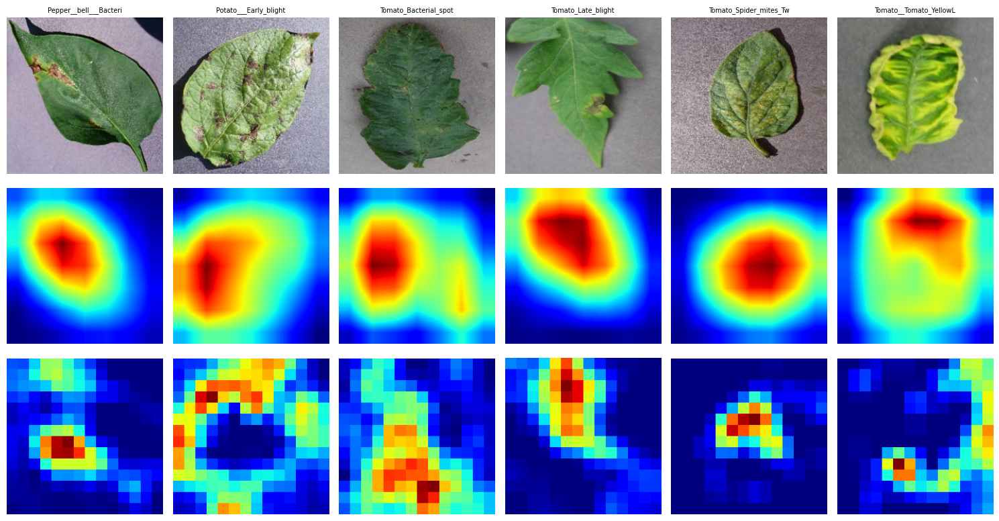

In [ ]:
# Saliency scoring: share of the attribution mass that lies on the leaf (set EXP)
EXP = "E2"  # run once with 'E0ga', once with 'E2'
PER_CLASS = 10  # images per class (fixed subset, plausible mask only)
rng = np.random.RandomState(2026)
y_np = Y.numpy()
subset = np.concatenate(
    [rng.permutation(np.where((y_np == k) & MASK_OK.numpy())[0])[:PER_CLASS] for k in range(15)]
)
methods = {"gradcam": gradcam, "gradient": gradsal, "occlusion": occlusion}
rows = []  # one row per (seed, image, method)
for seed in SEEDS:
    model = load_model(EXP, seed)
    pred = predict(model, X[subset]).argmax(1).numpy()
    for n, i in enumerate(subset):
        if pred[n] != y_np[i]:
            continue  # explain correct predictions only
        x = X[i : i + 1].float()
        m = M[i].numpy()
        for name, fn in methods.items():
            share, ratio = mass_on_leaf(fn(model, x, int(y_np[i])), m)
            rows.append((seed, int(i), int(y_np[i]), name, share, ratio, float(m.mean())))
print(
    f"{EXP}: {len(subset)} images chosen, mean over correct predictions and seeds {SEEDS}. ratio = mass on leaf / leaf area (1 = no preference for the leaf)."
)
print(
    f'{"method":11s}{"mass on leaf":>14s}{"leaf area":>12s}{"ratio":>8s}{"n":>8s}   {"ratio, rare classes":>20s}{"ratio, worst class":>30s}'
)
out = {}
for name in methods:
    r = [q for q in rows if q[3] == name and not np.isnan(q[5])]
    share, area, ratio = (np.mean([q[j] for q in r]) for j in (4, 6, 5))
    rr = [q[5] for q in r if q[2] in RI]
    per_k = {k: np.mean([q[5] for q in r if q[2] == k]) for k in range(15) if any(q[2] == k for q in r)}
    wk = min(per_k, key=per_k.get)
    out[name] = {
        "share": share,
        "area": area,
        "ratio": ratio,
        "ratio_rare": float(np.mean(rr)) if rr else None,
        "per_class_ratio": {classes[k]: v for k, v in per_k.items()},
    }
    print(
        f'{name:11s}{share:14.3f}{area:12.3f}{ratio:8.2f}{len(r):8d}   {np.mean(rr) if rr else float("nan"):20.2f}{classes[wk][:24] + f" {per_k[wk]:.2f}":>30s}'
    )
json.dump(
    {"exp": EXP, "summary": out, "rows": rows}, open(f"{PROJECT_ROOT}/runs/saliency_score_{EXP}.json", "w")
)
# picture: 6 images, original / Grad-CAM / occlusion
fig, ax = plt.subplots(3, 6, figsize=(15, 8))
model = load_model(EXP, 0)
for c, i in enumerate(subset[:: len(subset) // 6][:6]):
    x = X[i : i + 1].float()
    k = int(y_np[i])
    ax[0, c].imshow((x[0] * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy())
    ax[0, c].set_title(classes[k][:22], fontsize=7)
    ax[1, c].imshow(gradcam(model, x, k), cmap="jet")
    ax[2, c].imshow(occlusion(model, x, k), cmap="jet")
    for r in range(3):
        ax[r, c].axis("off")
plt.tight_layout()
plt.savefig(f"{PROJECT_ROOT}/runs/saliency_score_{EXP}.png", dpi=100)
plt.show()

In [ ]:
# Saliency comparison, E2 versus E0ga, per seed
import json, numpy as np

d = {e: json.load(open(f"{PROJECT_ROOT}/runs/saliency_score_{e}.json")) for e in ["E0ga", "E2"]}
SEEDS_ = [0, 42, 123]


def per_seed(e, method, col):  # rows: (seed, image, class, method, share, ratio, area)
    rows = [r for r in d[e]["rows"] if r[3] == method and not np.isnan(r[col])]
    return np.array([np.mean([r[col] for r in rows if r[0] == s]) for s in SEEDS_])


print("per-seed mean over correct predictions, mean ± sample std over seeds 0, 42, 123")
print(f'{"method":10s}{"E0ga ratio":>18s}{"E2 ratio":>18s}{"diff":>8s}{"E0ga mass":>18s}{"E2 mass":>18s}')
for m in ["gradcam", "gradient", "occlusion"]:
    a, b = per_seed("E0ga", m, 5), per_seed("E2", m, 5)
    ma, mb = per_seed("E0ga", m, 4), per_seed("E2", m, 4)
    f = lambda v: f"{v.mean():.3f} ± {v.std(ddof=1):.3f}"
    print(f"{m:10s}{f(a):>18s}{f(b):>18s}{b.mean() - a.mean():8.3f}{f(ma):>18s}{f(mb):>18s}")

per-seed mean over correct predictions, mean ± sample std over seeds 0, 42, 123
method            E0ga ratio          E2 ratio    diff         E0ga mass           E2 mass
gradcam        1.425 ± 0.006     1.475 ± 0.006   0.050     0.533 ± 0.001     0.550 ± 0.000
gradient       1.163 ± 0.014     1.254 ± 0.028   0.091     0.435 ± 0.005     0.465 ± 0.007
occlusion      1.273 ± 0.089     1.554 ± 0.046   0.281     0.478 ± 0.030     0.570 ± 0.016


/tmp/ipykernel_512/1034838493.py:30: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  c = [spearmanr(o.ravel(), n.ravel())[0] for o, n in zip(orig[name], new[name])]


E0ga seed 0, 40 correctly classified validation images. Spearman rank correlation with the map of the trained model (1 = unchanged).
Trusted tool: correlation falls towards 0 as more layers are randomised. A map that stays similar is explaining the input, not the model.
layers re-initialised (cumulative)        Grad-CAM    gradient   (maps without variance skipped: Grad-CAM / gradient)
up to fc                                     0.285       0.355   12 / 0
up to layer4                                -0.009       0.185   2 / 0
up to layer3                                 0.087       0.164   1 / 0
up to layer2                                 0.152       0.136   4 / 0
up to layer1                                 0.140       0.109   6 / 0
up to conv1+bn1                             -0.023       0.060   2 / 0


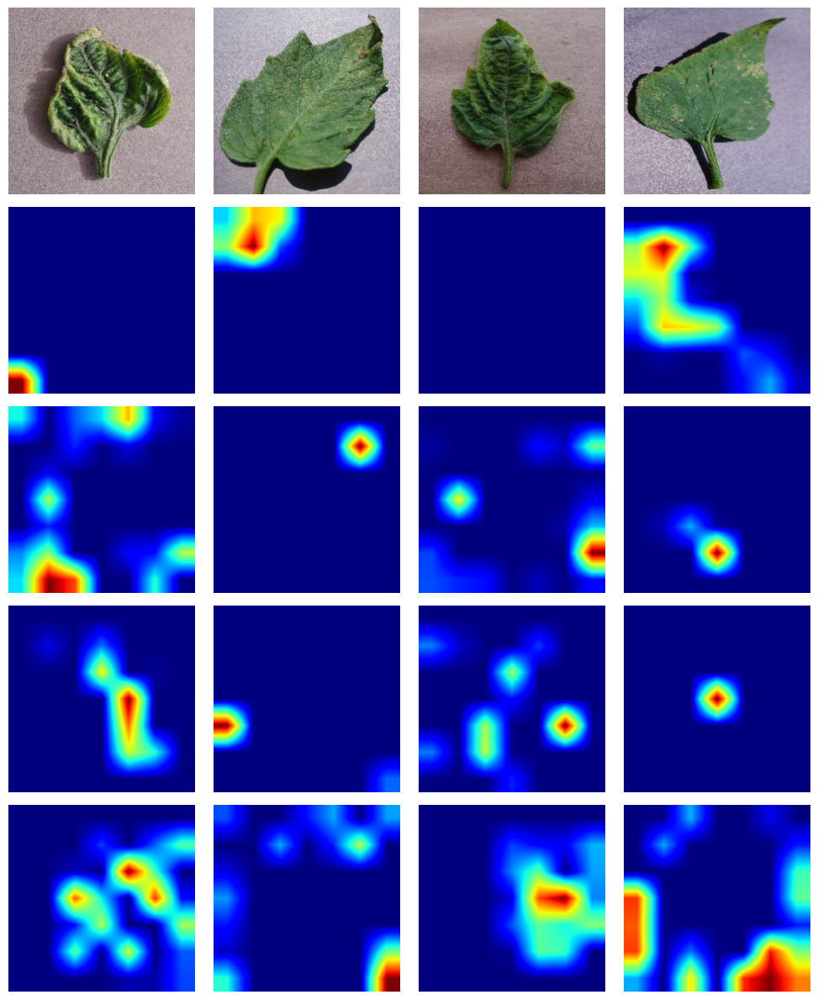

In [ ]:
# Randomisation sanity check for Grad-CAM and gradient saliency (Adebayo et al., 2018)
import copy
from scipy.stats import spearmanr

EXP = "E0ga"
N_IMG = 40
rng = np.random.RandomState(2026)
y_np = Y.numpy()
model0 = load_model(EXP, 0)
pred = predict(model0, X).argmax(1).numpy()
cand = np.where((pred == y_np) & MASK_OK.numpy())[0]
assert len(cand) > 0, "no correctly classified images with a plausible mask: check EXP and the checkpoint"
pick = rng.choice(cand, min(N_IMG, len(cand)), replace=False)
N_IMG = len(pick)
stages = [
    ("fc",),
    ("layer4",),
    ("layer3",),
    ("layer2",),
    ("layer1",),
    ("conv1", "bn1"),
]  # cumulative, top to bottom


def reinit(model, names):
    for nm in names:
        for mod in getattr(model, nm).modules():
            if hasattr(mod, "reset_parameters"):
                mod.reset_parameters()
    return model


orig = {
    "gradcam": [gradcam(model0, X[i : i + 1].float(), int(y_np[i])) for i in pick],
    "gradient": [gradsal(model0, X[i : i + 1].float(), int(y_np[i])) for i in pick],
}
corr = {"gradcam": [], "gradient": []}
labels = []
examples = {}
model = copy.deepcopy(model0)
torch.manual_seed(0)
for st in stages:
    model = reinit(model, st).eval()
    labels.append("+".join(st))
    new = {
        "gradcam": [gradcam(model, X[i : i + 1].float(), int(y_np[i])) for i in pick],
        "gradient": [gradsal(model, X[i : i + 1].float(), int(y_np[i])) for i in pick],
    }
    for name in corr:
        c = [spearmanr(o.ravel(), n.ravel())[0] for o, n in zip(orig[name], new[name])]
        c = [v for v in c if not np.isnan(v)]
        corr[name].append((float(np.mean(c)) if c else float("nan"), len(pick) - len(c)))
    examples[labels[-1]] = new["gradcam"][:4]
print(
    f"{EXP} seed 0, {N_IMG} correctly classified validation images. Spearman rank correlation with the map of the trained model (1 = unchanged)."
)
print(
    "Trusted tool: correlation falls towards 0 as more layers are randomised. A map that stays similar is explaining the input, not the model."
)
print(
    f'{"layers re-initialised (cumulative)":38s}{"Grad-CAM":>12s}{"gradient":>12s}   (maps without variance skipped: Grad-CAM / gradient)'
)
for k, lab in enumerate(labels):
    print(
        f'{"up to " + lab:38s}{corr["gradcam"][k][0]:12.3f}{corr["gradient"][k][0]:12.3f}   {corr["gradcam"][k][1]} / {corr["gradient"][k][1]}'
    )
json.dump(
    {"exp": EXP, "stages": labels, "corr": corr},
    open(f"{PROJECT_ROOT}/runs/saliency_randomisation_{EXP}.json", "w"),
)
fig, ax = plt.subplots(5, 4, figsize=(10, 12))
show_i = pick[:4]
for c, i in enumerate(show_i):
    ax[0, c].imshow((X[i].float() * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy())
    ax[0, c].axis("off")
    for r, lab in enumerate(["fc", "layer4", "layer2", "conv1+bn1"], start=1):
        ax[r, c].imshow(examples[lab][c], cmap="jet")
        ax[r, c].axis("off")
plt.tight_layout()
plt.savefig(f"{PROJECT_ROOT}/runs/saliency_randomisation_{EXP}.png", dpi=100)
plt.show()

In [ ]:
# Leaf-group check 1: example groups and purity numbers (never writes splits.json)
import os, re, json, numpy as np, pandas as pd
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

DATA_ROOT = "/content/data"  # train, val, test folders copied by the sanity check cell
CSV = f"{PROJECT_ROOT}/split_groups_v4.csv"  # written when split v4 was made (never rewrite it)
N_GROUPS = {"leaf_map": 10, "leaf_number": 4, "proxy": 6}  # groups shown per grouping method
PER_ROW = 8  # images per group shown
rng = np.random.RandomState(7)

df = pd.read_csv(CSV)
print(df.columns.tolist())
print(df.head(3).to_string())
print(len(df), "rows")
FILE_COL, GROUP_COL, SPLIT_COL, CLASS_COL, METHOD_COL = "rel", "group", "new_split", "cls", "method"
print(df[METHOD_COL].value_counts().to_string())

df["base"] = df[FILE_COL].astype(str).map(os.path.basename)
paths = {}  # basename -> real path in /content/data
for root, _, files in os.walk(DATA_ROOT):
    for f in files:
        paths[f] = os.path.join(root, f)
df["real"] = df["base"].map(paths)
print("csv rows with an image found on disk:", int(df["real"].notna().sum()), "of", len(df))
df = df[df["real"].notna()].copy()
df["cls"] = df["real"].map(lambda p: Path(p).parent.name)


def prefix(b):  # capture series prefix, for example RS_HL or Com.G_TgS_FL
    rest = b.split("___", 1)[-1]
    return re.split(r"[ 0-9]", rest, maxsplit=1)[0]


df["prefix"] = df["base"].map(prefix)


def kind_of(v):
    s = str(v).lower()
    return (
        "leaf_map"
        if "map" in s
        else (
            "leaf_number"
            if ("number" in s or "num" in s)
            else "proxy" if ("proxy" in s or "bucket" in s) else "other"
        )
    )


df["kind"] = df[METHOD_COL].map(kind_of)

# purity: does a group contain one class and one capture series, and how many images does it have?
g = df.groupby(GROUP_COL)
pur = pd.DataFrame(
    {
        "n": g.size(),
        "n_class": g["cls"].nunique(),
        "n_prefix": g["prefix"].nunique(),
        "n_split": g[SPLIT_COL].nunique(),
        "kind": g["kind"].first(),
    }
)
print("\nGroup purity (should be 1 class and 1 split everywhere, 1 capture series almost everywhere):")
for k, s in pur.groupby("kind"):
    print(
        f"  {k:12s} groups {len(s):5d} | median size {s.n.median():.0f}, max {s.n.max()} | groups with >1 class: {(s.n_class > 1).sum()} | >1 capture series: {(s.n_prefix > 1).sum()} | >1 split: {(s.n_split > 1).sum()}"
    )

# picture
kinds = [k for k in N_GROUPS if (pur.kind == k).any()] or ["unknown"]
rows = []
for k in kinds:
    cand = pur[(pur.kind == k) & (pur.n >= 4)].index.to_numpy()
    rows += [(k, gid) for gid in rng.choice(cand, min(N_GROUPS.get(k, 8), len(cand)), replace=False)]
if not rows:
    rows = [("any", gid) for gid in rng.choice(pur[pur.n >= 4].index.to_numpy(), 10, replace=False)]
fig, ax = plt.subplots(len(rows), PER_ROW, figsize=(PER_ROW * 1.6, len(rows) * 1.75))
ax = np.atleast_2d(ax)
for r, (k, gid) in enumerate(rows):
    sub = df[df[GROUP_COL] == gid].sort_values("base").head(PER_ROW)
    for c in range(PER_ROW):
        a = ax[r, c]
        a.axis("off")
        if c < len(sub):
            row = sub.iloc[c]
            a.imshow(Image.open(row["real"]).convert("RGB").resize((112, 112)))
            a.set_title(str(row[SPLIT_COL])[0], fontsize=6, pad=1)
    ax[r, 0].text(
        -0.05,
        0.5,
        f'{k}\n{sub.iloc[0]["cls"][:18]}\n{sub.iloc[0]["prefix"][:14]}',
        transform=ax[r, 0].transAxes,
        ha="right",
        va="center",
        fontsize=6,
    )
plt.suptitle(
    "Each row = one group (up to 8 images). Letter above an image = split (t/v). Same leaf = same plant and leaf in every image of the row.",
    fontsize=8,
)
plt.tight_layout()
out = f"{PROJECT_ROOT}/runs/group_check_montage.png"
plt.savefig(out, dpi=110)
plt.show()
print("saved", out)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# Leaf-number groups: sizes and the file names of the three largest
import pandas as pd

d = pd.read_csv(f"{PROJECT_ROOT}/split_groups_v4.csv")
ln = d[d["method"] == "leafnum"]
sz = ln.groupby("group").size().sort_values(ascending=False)
print(
    "leaf-number groups:",
    len(sz),
    "| single-image groups:",
    int((sz == 1).sum()),
    "| group size -> number of groups:",
    sz.value_counts().sort_index().to_dict(),
)
for g in sz.index[:3]:
    print("\n", g)
    print("\n".join(ln[ln["group"] == g]["rel"].map(lambda r: r.split("/")[-1]).tolist()))

leaf-number groups: 1497 | single-image groups: 1450 | group size -> number of groups: {1: 1450, 2: 31, 3: 10, 4: 2, 5: 2, 6: 2}

 Tomato_Late_blight|ln|GHLB_PS|leaf1
373403cf-6ba1-441e-bd8a-590578b67ba7___GHLB_PS Leaf 1 Day 16.jpg
674de9c3-1e13-46e2-9d5d-f75f97cff552___GHLB_PS Leaf 1 Day 18.jpg
7e10e4ed-19e9-4e89-a936-4b2bb30d4e90___GHLB_PS Leaf 1 Day 13.jpg
89d2801e-6359-4079-a4c2-0df4718d7800___GHLB_PS Leaf 1 Day 8.jpg
d5f68aaa-5700-4957-b08c-dcab8be0d49e___GHLB_PS Leaf 1 Day 9.jpg
7d4d00c0-1e72-427d-9f05-1f64f8051cb8___GHLB_PS Leaf 1 Day 7.jpg

 Tomato_Late_blight|ln|GHLB|leaf2
3a1a6b9e-2a68-421f-adbe-229baf8a6093___GHLB Leaf 2 Day 13.JPG
3e01dcb7-e660-4403-861a-59a44d572565___GHLB Leaf 2 Day 7.JPG
5c2e8475-ec0a-4566-af20-a4dedf3dc1c0___GHLB Leaf 2 Day 1.JPG
77793164-1671-42f7-83a2-f13074ec4892___GHLB Leaf 2 Day 6.JPG
d45e9f86-2819-4c41-886c-73b7012674b3___GHLB Leaf 2 Day 16 .JPG
d9459215-359a-48d1-babe-be3b7b11cd9d___GHLB Leaf 2 Day 12.JPG

 Tomato_Late_blight|ln|GHLB_PS|leaf8
c11

In [ ]:
# Leaf-group check 2: nearest-neighbour similarity of validation to training images
import os, json, numpy as np, pandas as pd, torch, torchvision
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

DATA_ROOT = "/content/data"
CSV = f"{PROJECT_ROOT}/split_groups_v4.csv"
RANDOM_SPLIT = f"{PROJECT_ROOT}/splits_v2_dedup.json"  # the random split (val 2,060, test 2,069) before the leaf-grouped split
rng = np.random.RandomState(7)

# 1) ImageNet ResNet-18 embeddings of every image on disk (no fine-tuning)
files = sorted(str(p) for p in Path(DATA_ROOT).rglob("*") if p.suffix.lower() in (".jpg", ".jpeg", ".png"))
tf = T.Compose(
    [T.Resize((224, 224)), T.ToTensor(), T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])]
)


class Imgs(Dataset):
    def __len__(self):
        return len(files)

    def __getitem__(self, i):
        return tf(Image.open(files[i]).convert("RGB"))


net = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
net.fc = torch.nn.Identity()
net = net.to(device).eval()
emb = []
with torch.no_grad():
    for x in DataLoader(Imgs(), batch_size=128, num_workers=2):
        emb.append(torch.nn.functional.normalize(net(x.to(device)), dim=1).cpu())
E = torch.cat(emb)
base = [os.path.basename(f) for f in files]
idx = {b: i for i, b in enumerate(base)}
cls_of = np.array([Path(f).parent.name for f in files])
print("embedded", len(files), "images")

# 2) split membership: v4 from the folders, random split from splits_v2_dedup.json
v4 = np.array([Path(f).parent.parent.name for f in files])  # 'train', 'val' or 'test'
raw = json.load(open(RANDOM_SPLIT))
raw = raw.get("splits", raw)
rand = np.array(["none"] * len(files), dtype=object)
for sp in ("train", "val", "test"):
    for p in raw[sp]:
        i = idx.get(os.path.basename(str(p)))
        if i is not None:
            rand[i] = sp
print(
    "images found per split | v4:",
    {s: int((v4 == s).sum()) for s in ("train", "val", "test")},
    "| random:",
    {s: int((rand == s).sum()) for s in ("train", "val", "test", "none")},
)

# 3) positive control (same leaf group) and negative control (random pair of the same class)
df = pd.read_csv(CSV)
fcol, gcol = "rel", "group"
df["i"] = df[fcol].astype(str).map(lambda p: idx.get(os.path.basename(p)))
df = df[df["i"].notna()].copy()
df["i"] = df["i"].astype(int)
pos, neg = [], []
mcol = "method"
df_pos = df[
    df[mcol].astype(str).str.contains("map")
]  # positive control from leaf-map groups only (the most trusted ones)
groups = df_pos.groupby(gcol)["i"].apply(list)
groups = groups[groups.map(len) >= 2]
for gid, members in groups.sample(min(3000, len(groups)), random_state=7).items():
    a, b = rng.choice(members, 2, replace=False)
    pos.append(float(E[a] @ E[b]))
    same = np.where(cls_of == cls_of[a])[0]
    c = rng.choice(same)
    if c not in members:
        neg.append(float(E[a] @ E[c]))
pos, neg = np.array(pos), np.array(neg)
tau = float(np.percentile(pos, 25))
print(
    f"\nPositive control: cosine similarity of two images of the SAME leaf-map group mean {pos.mean():.3f}, 25th percentile {tau:.3f}"
)
print(
    f"Negative control: two random images of the same class, different group     mean {neg.mean():.3f}, 75th percentile {np.percentile(neg, 75):.3f}"
)
print(
    "The controls must be clearly apart (positive well above negative), otherwise similarity cannot tell siblings from other leaves of the class."
)


# 4) nearest training neighbour of every validation image
def nn_sim(split_vec):
    tr = torch.where(torch.tensor(split_vec == "train"))[0]
    va = torch.where(torch.tensor(split_vec == "val"))[0]
    out = []
    for k in range(0, len(va), 512):
        out.append((E[va[k : k + 512]] @ E[tr].T).max(1).values)
    return va.numpy(), torch.cat(out).numpy()


kind_of_img = {int(i): m for i, m in zip(df["i"], df[mcol])}
print(
    f"\nNearest training image for every validation image (cosine similarity). tau = {tau:.3f} (25th percentile of same-leaf pairs)"
)
print(f'{"split":14s}{"val images":>11s}{"mean":>8s}{"median":>8s}{"share >= tau":>14s}')
res = {}
for name, vec in [("random", rand), ("v4 leaf-grouped", v4)]:
    va, sim = nn_sim(vec)
    res[name] = sim
    print(f"{name:14s}{len(sim):11d}{sim.mean():8.3f}{np.median(sim):8.3f}{(sim >= tau).mean():14.3f}")
    if kind_of_img:
        kinds = np.array([kind_of_img.get(int(i), "none") for i in va])
        for k in sorted(set(kinds)):
            q = sim[kinds == k]
            print(
                f"   by grouping method {k:10s}{len(q):6d}{q.mean():8.3f}{np.median(q):8.3f}{(q >= tau).mean():14.3f}"
            )
json.dump(
    {
        "tau": tau,
        "pos_mean": float(pos.mean()),
        "neg_mean": float(neg.mean()),
        "nn": {k: [float(np.mean(v)), float(np.median(v)), float((v >= tau).mean())] for k, v in res.items()},
    },
    open(f"{PROJECT_ROOT}/runs/leaf_group_nn_check.json", "w"),
)

embedded 61909 images
images found per split | v4: {'train': 16456, 'val': 2100, 'test': 2077} | random: {'train': 16504, 'val': 2060, 'test': 2069, 'none': 41276}

Positive control: cosine similarity of two images of the SAME leaf-map group mean 0.893, 25th percentile 0.873
Negative control: two random images of the same class, different group     mean 0.821, 75th percentile 0.856
The controls must be clearly apart (positive well above negative), otherwise similarity cannot tell siblings from other leaves of the class.

Nearest training image for every validation image (cosine similarity). tau = 0.873 (25th percentile of same-leaf pairs)
split          val images    mean  median  share >= tau
random               2060   0.929   0.930         0.986
   by grouping method leafmap     1500   0.925   0.927         0.981
   by grouping method leafnum      155   0.946   0.953         1.000
   by grouping method proxy        405   0.937   0.935         1.000
v4 leaf-grouped       2100   0.920

## Figures

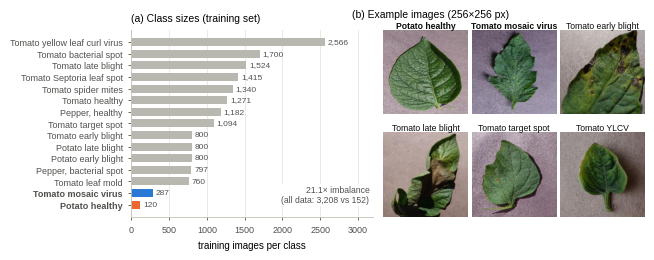

saved /content/drive/MyDrive/Søren og Magnus/Deep Learning /Project_deep/figures/fig1_data.pdf
Fig 2 mean val acc per fraction: {2: 0.8668, 5: 0.9381, 10: 0.9687, 25: 0.9817, 100: 0.9954} (compare with STATUS)


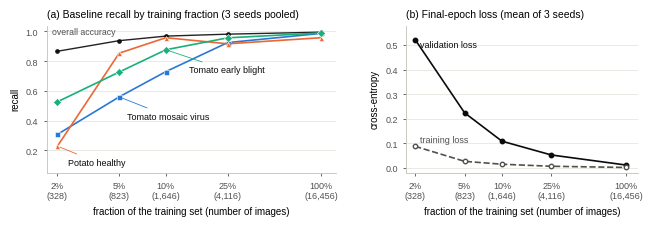

saved /content/drive/MyDrive/Søren og Magnus/Deep Learning /Project_deep/figures/fig2_fraction.pdf
Fig 3 rare group, correct of 207 (pooled) vs STATUS:
  100% Baseline       203 (STATUS 203) per seed [68, 69, 66] [file]
  100% Weighted loss  205 (STATUS 205) per seed [68, 69, 68] [file]
  100% Focal loss     202 (STATUS 202) per seed [68, 66, 68] [file]
  100% Oversampling   206 (STATUS 206) per seed [69, 68, 69] [file]
   10% Baseline       162 (STATUS 162) per seed [44, 58, 60] [file]
   10% Weighted loss  180 (STATUS 180) per seed [49, 66, 65] [file]
   10% Focal loss     145 (STATUS 145) per seed [39, 55, 51] [file]
   10% Oversampling   170 (STATUS 170) per seed [59, 62, 49] [file]
    5% Baseline       130 (STATUS 130) per seed [43, 48, 39] [file]
    5% Weighted loss  165 (STATUS 165) per seed [58, 59, 48] [file]
    5% Focal loss     107 (STATUS 107) per seed [33, 41, 33] [file]
    5% Oversampling   164 (STATUS 164) per seed [49, 60, 55] [file]
    2% Baseline        60 (STATU

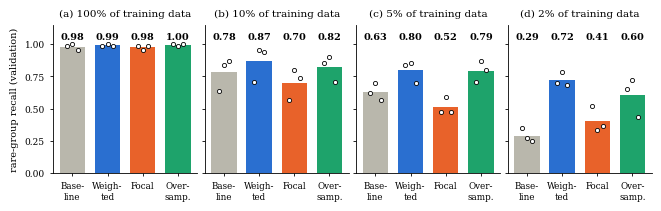

saved /content/drive/MyDrive/Søren og Magnus/Deep Learning /Project_deep/figures/fig3_methods.pdf


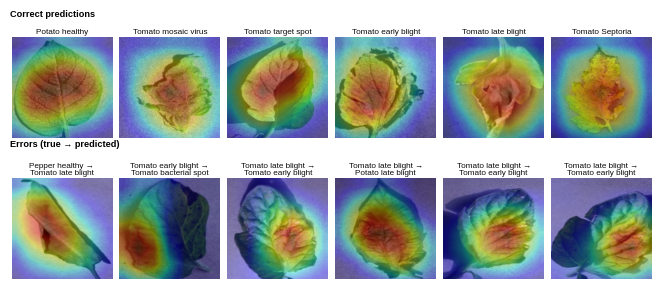

saved /content/drive/MyDrive/Søren og Magnus/Deep Learning /Project_deep/figures/fig4_gradcam.pdf
Fig 5 hull  Baseline               original: 0.9955 ± 0.0015, same_class_bg: 0.9642 ± 0.0039, other_class_bg: 0.8608 ± 0.0150, grey_bg: 0.8332 ± 0.0149
Fig 5 hull  Stronger augmentation  original: 0.9939 ± 0.0003, same_class_bg: 0.9698 ± 0.0045, other_class_bg: 0.8810 ± 0.0097, grey_bg: 0.8772 ± 0.0151
Fig 5 tight Baseline               original: 0.9954 ± 0.0015, same_class_bg: 0.9145 ± 0.0109, other_class_bg: 0.6649 ± 0.0198, grey_bg: 0.6334 ± 0.0225
Fig 5 tight Stronger augmentation  original: 0.9938 ± 0.0003, same_class_bg: 0.9270 ± 0.0145, other_class_bg: 0.7268 ± 0.0337, grey_bg: 0.6809 ± 0.0047


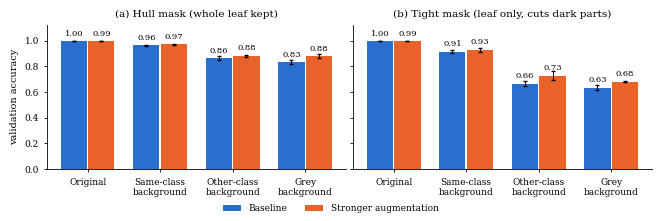

saved /content/drive/MyDrive/Søren og Magnus/Deep Learning /Project_deep/figures/fig5_swap.pdf

All figures saved in /content/drive/MyDrive/Søren og Magnus/Deep Learning /Project_deep/figures . Download the five PDFs and put them in the figures/ folder in Overleaf.
Not read from result files (check against STATUS if anything changed):
 - Fig 1a class counts are typed in from STATUS section 3 (totals checked: 16,456 / 2,100 / 2,077).
 - Fig 1b: example images are the first image of each class in the train folder (not the same images as Magnus's version).
 - Fig 2a per-class recall lines are typed in from STATUS; accuracy line and Fig 2b are read from runs/experiment_log.csv.
 - Fig 4: panel titles are typed in and match the order of images in runs/E0ga_gradcam_seed0.png; check by eye that each title fits its image.


[None, None, None, None]

In [ ]:
# Report figures 1 to 5, saved as PDF and PNG in figures/
import json, os, numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image

# settings
U = Path(PROJECT_ROOT)  # holds runs/, frac_f10/, frac_f05/, frac_f02/
OUT = U / "figures"
OUT.mkdir(exist_ok=True)
DATA = Path("/content/data")
IMG_OVERRIDE = (
    U / "figures_src" / "img"
)  # optional folder with hand-picked example images, named <class folder>.JPG
RARE = ["Potato___healthy", "Tomato__Tomato_mosaic_virus"]  # class names exactly as in the result files
N_RARE_VAL = 69  # Potato healthy 16 + Tomato mosaic virus 53 (validation, split v4)

# style
avail = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ["Liberation Sans", "Arial", "DejaVu Sans"] if f in avail), "DejaVu Sans")
plt.rcParams.update(
    {
        "font.family": FONT,
        "font.size": 7,
        "axes.titlesize": 7.5,
        "axes.labelsize": 7,
        "xtick.labelsize": 6.5,
        "ytick.labelsize": 6.5,
        "axes.linewidth": 0.6,
        "xtick.major.width": 0.6,
        "ytick.major.width": 0.6,
        "xtick.major.size": 2.5,
        "ytick.major.size": 2.5,
        "pdf.fonttype": 42,
        "savefig.dpi": 300,
    }
)
INK = "#0b0b0b"
INK2 = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
AX = "#c3c2b7"
BLUE = "#2a78d6"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
GRAY = "#b9b8b0"


def style(ax, grid="y"):
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_color(AX)
    ax.tick_params(colors=INK2)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.5)
        ax.set_axisbelow(True)


def done(fig, name):
    fig.savefig(OUT / f"{name}.pdf")
    fig.savefig(OUT / f"{name}.png", dpi=200)
    plt.show()
    plt.close(fig)
    print("saved", OUT / f"{name}.pdf")


# Fig 1: data
counts = {  # class: (train, val, test) images, split v4
    "Pepper, bacterial spot": (797, 100, 100),
    "Pepper, healthy": (1182, 148, 148),
    "Potato early blight": (800, 100, 100),
    "Potato late blight": (800, 100, 100),
    "Potato healthy": (120, 16, 16),
    "Tomato bacterial spot": (1700, 215, 212),
    "Tomato early blight": (800, 100, 100),
    "Tomato late blight": (1524, 191, 191),
    "Tomato leaf mold": (760, 96, 96),
    "Tomato Septoria leaf spot": (1415, 178, 178),
    "Tomato spider mites": (1340, 168, 168),
    "Tomato target spot": (1094, 155, 155),
    "Tomato yellow leaf curl virus": (2566, 321, 321),
    "Tomato mosaic virus": (287, 53, 33),
    "Tomato healthy": (1271, 159, 159),
}
assert (
    sum(v[0] for v in counts.values()) == 16456
    and sum(v[1] for v in counts.values()) == 2100
    and sum(v[2] for v in counts.values()) == 2077
)
names = sorted(counts, key=lambda k: counts[k][0])
col = {"Potato healthy": ORANGE, "Tomato mosaic virus": BLUE}
fig = plt.figure(figsize=(6.5, 2.55))
gs = fig.add_gridspec(
    1, 2, width_ratios=[1.0, 1.08], wspace=0.04, left=0.205, right=0.995, top=0.905, bottom=0.17
)
ax = fig.add_subplot(gs[0])
y = np.arange(len(names))
ax.barh(
    y, [counts[n][0] for n in names], color=[col.get(n, GRAY) for n in names], height=0.68, edgecolor="none"
)
for yi, n in zip(y, names):
    ax.text(counts[n][0] + 35, yi, f"{counts[n][0]:,}", va="center", ha="left", fontsize=6, color=INK2)
ax.set_yticks(y)
ax.set_yticklabels(names)
for t in ax.get_yticklabels():
    if t.get_text() in col:
        t.set_fontweight("bold")
        t.set_color(INK)
ax.set_xlim(0, 3200)
ax.set_xlabel("training images per class")
style(ax, "x")
ax.set_title("(a) Class sizes (training set)", loc="left", fontsize=7.5)
ax.text(
    3150,
    0.0,
    "21.1× imbalance\n(all data: 3,208 vs 152)",
    ha="right",
    va="bottom",
    fontsize=6.2,
    color=INK2,
    bbox=dict(fc="white", ec="none", pad=1.2),
)
imgs = [
    ("Potato___healthy", "Potato healthy"),
    ("Tomato___Tomato_mosaic_virus", "Tomato mosaic virus"),
    ("Tomato___Early_blight", "Tomato early blight"),
    ("Tomato___Late_blight", "Tomato late blight"),
    ("Tomato___Target_Spot", "Tomato target spot"),
    ("Tomato___Tomato_Yellow_Leaf_Curl_Virus", "Tomato YLCV"),
]


def example_image(folder):
    if IMG_OVERRIDE.is_dir():
        for p in IMG_OVERRIDE.iterdir():
            if p.stem == folder:
                return Image.open(p).convert("RGB")
    norm = lambda s: s.lower().replace("_", "")
    for d in sorted((DATA / "train").iterdir()):  # class folder names may differ in the number of underscores
        if d.is_dir() and norm(d.name) == norm(folder):
            f = sorted(p for p in d.iterdir() if p.suffix.lower() in (".jpg", ".jpeg", ".png"))[0]
            return Image.open(f).convert("RGB")
    raise FileNotFoundError(f"no example image for {folder}: set IMG_OVERRIDE or DATA")


gs2 = gs[1].subgridspec(2, 3, wspace=0.05, hspace=0.2)
fig.text(0.545, 0.965, "(b) Example images (256×256 px)", fontsize=7.5, ha="left", va="center")
for i, (f, lab) in enumerate(imgs):
    a = fig.add_subplot(gs2[i // 3, i % 3])
    a.imshow(example_image(f))
    a.axis("off")
    a.set_title(
        lab,
        fontsize=6.2,
        pad=1.5,
        color=INK,
        fontweight="bold" if lab in ("Potato healthy", "Tomato mosaic virus") else "normal",
    )
done(fig, "fig1_data")

# Fig 2: baseline versus training fraction
log = pd.read_csv(U / "runs" / "experiment_log.csv")
frac = {"E0f02": 2, "E0f05": 5, "E0f10": 10, "E0f25": 25, "E0ga": 100}
ntr = {2: 328, 5: 823, 10: 1646, 25: 4116, 100: 16456}
fr = sorted(frac.values())


def seeds(e, c):
    return log[log.experiment == e].sort_values("seed")[c].values


acc = {frac[e]: seeds(e, "val_acc") for e in frac}
trl = [np.mean(seeds(e, "train_loss_final")) for e in sorted(frac, key=lambda k: frac[k])]
vll = [np.mean(seeds(e, "val_loss_final")) for e in sorted(frac, key=lambda k: frac[k])]
fig, axs = plt.subplots(
    1,
    2,
    figsize=(6.5, 2.3),
    gridspec_kw=dict(wspace=0.27, left=0.075, right=0.985, top=0.89, bottom=0.25, width_ratios=[1.25, 1]),
)
ax = axs[0]
rec = {
    "Tomato mosaic virus (rare)": (
        [0.308, 0.560, 0.730, 0.925, 0.987],
        BLUE,
        "s",
    ),  # per-class recall, pooled over the three seeds
    "Potato healthy (rare)": ([0.229, 0.854, 0.958, 0.917, 0.958], ORANGE, "^"),
    "Tomato early blight": ([0.527, 0.727, 0.877, 0.957, 0.990], AQUA, "D"),
}
am = [np.mean(acc[f]) for f in fr]
ax.plot(fr, am, color=INK, lw=1.0, ls="-", alpha=0.9, marker="o", ms=2.4)
for k, (v, c, m) in rec.items():
    ax.plot(fr, v, color=c, marker=m, ms=3.6, lw=1.2, mec="white", mew=0.4)
ax.annotate(
    "Tomato mosaic virus",
    (5, 0.56),
    xytext=(5.6, 0.43),
    fontsize=6.5,
    color=INK,
    ha="left",
    va="center",
    arrowprops=dict(arrowstyle="-", color=BLUE, lw=0.6),
)
ax.annotate(
    "Potato healthy",
    (2, 0.229),
    xytext=(2.35, 0.12),
    fontsize=6.5,
    color=INK,
    ha="left",
    va="center",
    arrowprops=dict(arrowstyle="-", color=ORANGE, lw=0.6),
)
ax.annotate(
    "Tomato early blight",
    (10, 0.877),
    xytext=(14, 0.74),
    fontsize=6.5,
    color=INK,
    ha="left",
    va="center",
    arrowprops=dict(arrowstyle="-", color=AQUA, lw=0.6),
)
ax.text(1.85, 0.97, "overall accuracy", color=INK2, fontsize=6.3, ha="left", va="bottom")
ax.set_title("(a) Baseline recall by training fraction (3 seeds pooled)", loc="left")
ax.set_ylim(0.05, 1.04)
ax.set_ylabel("recall")
ax = axs[1]
ax.plot(fr, vll, color=INK, marker="o", ms=3.2, lw=1.2)
ax.plot(fr, trl, color=INK2, marker="o", ms=3.2, lw=1.2, ls="--", mfc="white")
ax.text(2.2, 0.50, "validation loss", color=INK, fontsize=6.5, ha="left", va="center")
ax.text(2.2, 0.115, "training loss", color=INK2, fontsize=6.5, ha="left", va="center")
ax.set_title("(b) Final-epoch loss (mean of 3 seeds)", loc="left")
ax.set_ylim(-0.02, 0.58)
ax.set_ylabel("cross-entropy")
for ax in axs:
    ax.set_xscale("log")
    ax.set_xlim(1.7, 125)
    ax.set_xticks(fr)
    ax.set_xticklabels([f"{f}%\n({ntr[f]:,})" for f in fr])
    ax.minorticks_off()
    ax.set_xlabel("fraction of the training set (number of images)")
    style(ax, "y")
print("Fig 2 mean val acc per fraction:", {f: round(float(np.mean(acc[f])), 4) for f in fr})
done(fig, "fig2_fraction")


# Fig 3: rare-group recall, four fractions
def rare_correct(path):
    """Correct rare-group images per seed (of 69), from the validation confusion matrices."""
    d = json.load(open(U / path))
    ri = [d["classes"].index(c) for c in RARE]
    out = []
    for r in sorted(d["results"], key=lambda r: r["seed"]):
        cm = np.array(r["val"]["confusion_matrix"])
        out.append(int(sum(cm[i, i] for i in ri)))
    return out


FILES = {
    "100": ["runs/E0ga.json", "runs/E1a.json", "runs/E1b.json", "runs/E1c.json"],
    "10": ["runs/E0f10.json"] + [f"frac_f10/runs/{e}.json" for e in ("E1a", "E1b", "E1c")],
    "5": ["runs/E0f05.json"] + [f"frac_f05/runs/{e}.json" for e in ("E1a", "E1b", "E1c")],
    "2": ["runs/E0f02.json"] + [f"frac_f02/runs/{e}.json" for e in ("E1a", "E1b", "E1c")],
}
meth = ["Baseline", "Weighted loss", "Focal loss", "Oversampling"]
C3 = ["#b9b7ac", "#2a6fd0", "#e8622a", "#1ea36b"]
R = {}
print("Fig 3 rare group, correct of 207 (pooled):")
for fz in ["100", "10", "5", "2"]:
    R[fz] = {}
    for m, f in zip(meth, FILES[fz]):
        R[fz][m] = rare_correct(f)
        print(f"  {fz:>3}% {m:13s} {sum(R[fz][m]):>4} per seed {R[fz][m]}")
# Drawing: bars = pooled recall, circles = single seeds
LAB = ["Base-\nline", "Weigh-\nted", "Focal", "Over-\nsamp."]
with plt.rc_context(
    {"font.family": "serif", "font.size": 7.5, "axes.spines.top": False, "axes.spines.right": False}
):
    fig, axs = plt.subplots(1, 4, figsize=(6.5, 2.0), sharey=True)
    for ax, fz, lab in zip(axs, ["100", "10", "5", "2"], "abcd"):
        for i, m in enumerate(meth):
            v = R[fz][m]
            pooled = sum(v) / (3 * N_RARE_VAL)
            ax.bar(i, pooled, color=C3[i], width=0.72)
            ax.scatter(
                [i - 0.15, i, i + 0.15],
                [x / N_RARE_VAL for x in v],
                s=9,
                facecolor="white",
                edgecolor="k",
                linewidth=0.6,
                zorder=3,
            )
            ax.text(i, 1.04, f"{pooled:.2f}", ha="center", fontsize=7, fontweight="bold")
        ax.set_title(f"({lab}) {fz}% of training data", fontsize=7.5)
        ax.set_xticks(range(4))
        ax.set_xticklabels(LAB, fontsize=6.3)
        ax.set_ylim(0, 1.15)
        ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
    axs[0].set_ylabel("rare-group recall (validation)")
    plt.tight_layout(pad=0.4)
    done(fig, "fig3_methods")

# Fig 4: Grad-CAM panels cut from runs/E0ga_gradcam_seed0.png
g = Image.open(U / "runs" / "E0ga_gradcam_seed0.png").convert("RGB")
if g.size[0] < 2318 or g.size[1] < 873:
    print(
        "WARNING: the Grad-CAM image has size",
        g.size,
        "and the crop boxes below are meant for a larger image; the panels may be cut wrongly",
    )
cx = [(23, 387), (409, 773), (795, 1159), (1181, 1545), (1568, 1932), (1954, 2318)]
ry = [(109, 473), (509, 873)]
top = [
    "Potato healthy",
    "Tomato mosaic virus",
    "Tomato target spot",
    "Tomato early blight",
    "Tomato late blight",
    "Tomato Septoria",
]
bot = [
    "Pepper healthy →\nTomato late blight",
    "Tomato early blight →\nTomato bacterial spot",
    "Tomato late blight →\nTomato early blight",
    "Tomato late blight →\nPotato late blight",
    "Tomato late blight →\nTomato early blight",
    "Tomato late blight →\nTomato early blight",
]
fig, axs = plt.subplots(
    2,
    6,
    figsize=(6.5, 2.7),
    gridspec_kw=dict(wspace=0.04, hspace=0.40, left=0.005, right=0.995, top=0.90, bottom=0.005),
)
for r in range(2):
    for c in range(6):
        a = axs[r, c]
        a.imshow(g.crop((cx[c][0] + 14, ry[r][0], cx[c][0] + 350, ry[r][0] + 336)))
        a.axis("off")
        a.set_title(top[c] if r == 0 else bot[c], fontsize=5.9, pad=2.5, color=INK, linespacing=1.0)
fig.text(0.005, 0.985, "Correct predictions", fontsize=6.6, fontweight="bold", va="center", ha="left")
fig.text(0.005, 0.505, "Errors (true → predicted)", fontsize=6.6, fontweight="bold", va="center", ha="left")
done(fig, "fig4_gradcam")

# Fig 5: background swap (validation accuracy per condition)
COND = [
    ("original", "Original"),
    ("same_class_bg", "Same-class\nbackground"),
    ("other_class_bg", "Other-class\nbackground"),
    ("grey_bg", "Grey\nbackground"),
]


def swap_stats(tag):
    d = json.load(open(U / "runs" / f"background_swap_{tag}.json"))
    return [np.mean([r["acc"] for r in d["res"][c]]) for c, _ in COND], [
        np.std([r["acc"] for r in d["res"][c]], ddof=1) for c, _ in COND
    ]


with plt.rc_context(
    {"font.family": "serif", "font.size": 7.5, "axes.spines.top": False, "axes.spines.right": False}
):
    fig, axs = plt.subplots(1, 2, figsize=(6.5, 2.1), sharey=True)
    for ax, (mode, title) in zip(
        axs,
        [
            ("hull", "(a) Hull mask (whole leaf kept)"),
            ("tight", "(b) Tight mask (leaf only, cuts dark parts)"),
        ],
    ):
        x = np.arange(4)
        for j, (exp, c, label) in enumerate(
            [("E0ga", "#2a6fd0", "Baseline"), ("E2", "#e8622a", "Stronger augmentation")]
        ):
            m, sd = swap_stats(exp + ("_hull" if mode == "hull" else ""))
            ax.bar(
                x + (j - 0.5) * 0.38,
                m,
                0.36,
                yerr=sd,
                color=c,
                label=label,
                capsize=1.5,
                error_kw={"lw": 0.7},
            )
            for xi, mi in zip(x, m):
                ax.text(xi + (j - 0.5) * 0.38, mi + 0.045, f"{mi:.2f}", ha="center", fontsize=6)
            print(
                f"Fig 5 {mode:5s} {label:22s} "
                + ", ".join(f"{k}: {a:.4f} ± {e:.4f}" for (k, _), a, e in zip(COND, m, sd))
            )
        ax.set_xticks(x)
        ax.set_xticklabels([l for _, l in COND], fontsize=6.5)
        ax.set_title(title, fontsize=7.5)
        ax.set_ylim(0, 1.12)
    axs[0].set_ylabel("validation accuracy")
    h, l = axs[0].get_legend_handles_labels()
    fig.legend(h, l, fontsize=6.5, frameon=False, loc="lower center", ncol=2)
    plt.tight_layout(pad=0.4, rect=(0, 0.07, 1, 1))
    done(fig, "fig5_swap")

In [ ]:
# Checkpoint check: the 51 checkpoints needed for the final test evaluation
from pathlib import Path

SEEDS_CHECK = [0, 42, 123]
MODELS_CHECK = [
    ("E0ga", PROJECT_ROOT),
    ("E1a", PROJECT_ROOT),
    ("E1b", PROJECT_ROOT),
    ("E1c", PROJECT_ROOT),
    ("E2", PROJECT_ROOT),
    ("E0f10", PROJECT_ROOT),
    ("E1a", f"{PROJECT_ROOT}/frac_f10"),
    ("E1b", f"{PROJECT_ROOT}/frac_f10"),
    ("E1c", f"{PROJECT_ROOT}/frac_f10"),
    ("E0f05", PROJECT_ROOT),
    ("E1a", f"{PROJECT_ROOT}/frac_f05"),
    ("E1b", f"{PROJECT_ROOT}/frac_f05"),
    ("E1c", f"{PROJECT_ROOT}/frac_f05"),
    ("E0f02", PROJECT_ROOT),
    ("E1a", f"{PROJECT_ROOT}/frac_f02"),
    ("E1b", f"{PROJECT_ROOT}/frac_f02"),
    ("E1c", f"{PROJECT_ROOT}/frac_f02"),
]
missing, ok = [], 0
for exp_id, root in MODELS_CHECK:
    for seed in SEEDS_CHECK:
        p = Path(root) / "checkpoints" / f"{exp_id}_seed{seed}.pt"
        if p.exists() and p.stat().st_size > 10_000_000:
            ok += 1
        else:
            missing.append(str(p))
    t = Path(root) / "runs" / f"{exp_id}_test.json"
    if t.exists():
        print("WARNING: a test file already exists for", exp_id, "in", root)
print(f"checkpoints found: {ok} of {len(MODELS_CHECK) * len(SEEDS_CHECK)}")
print("missing or too small:" if missing else "all checkpoints are there")
print("\n".join(missing))

checkpoints found: 51 of 51
all checkpoints are there



In [ ]:
# Contents of the 2% checkpoint and result folders, search for E1c checkpoints
from pathlib import Path

R = Path(PROJECT_ROOT)
for sub in ["frac_f02/checkpoints", "frac_f02/runs"]:
    d = R / sub
    print(f"--- {sub}:", "MISSING FOLDER" if not d.exists() else "")
    if d.exists():
        for p in sorted(d.iterdir()):
            print(f"  {p.name:40s}{p.stat().st_size/1e6:9.1f} MB")
print("--- all files with E1c in the name under the project (checkpoints):")
for p in sorted(R.rglob("*E1c*.pt")):
    print(f"  {str(p.relative_to(R)):70s}{p.stat().st_size/1e6:9.1f} MB")

--- frac_f02/checkpoints: 
  E1a_seed0.pt                                 44.8 MB
  E1a_seed123.pt                               44.8 MB
  E1a_seed42.pt                                44.8 MB
  E1b_seed0.pt                                 44.8 MB
  E1b_seed123.pt                               44.8 MB
  E1b_seed42.pt                                44.8 MB
--- frac_f02/runs: 
  E1a.json                                      0.1 MB
  E1b.json                                      0.1 MB
  E1c.json                                      0.1 MB
  experiment_log.csv                            0.0 MB
--- all files with E1c in the name under the project (checkpoints):
  checkpoints/E1c_seed0.pt                                                   44.8 MB
  checkpoints/E1c_seed123.pt                                                 44.8 MB
  checkpoints/E1c_seed42.pt                                                  44.8 MB
  frac_f05/checkpoints/E1c_seed0.pt                                          44.

In [ ]:
# Modification times of the E1c checkpoints and result files
from pathlib import Path
from datetime import datetime

R = Path(PROJECT_ROOT)
files = (
    [R / f"checkpoints/E1c_seed{s}.pt" for s in (0, 42, 123)]
    + [R / "runs/E1c.json", R / "runs/E1b.json", R / "runs/E0f02.json"]
    + [R / f"frac_f10/checkpoints/E1c_seed{s}.pt" for s in (0, 42, 123)]
    + [R / "frac_f10/runs/E1c.json"]
    + [R / f"frac_f05/checkpoints/E1c_seed{s}.pt" for s in (0, 42, 123)]
    + [
        R / "frac_f02/runs/E1a.json",
        R / "frac_f02/runs/E1b.json",
        R / "frac_f02/runs/E1c.json",
        R / "frac_f02/runs/experiment_log.csv",
    ]
    + [R / f"frac_f02/checkpoints/E1b_seed{s}.pt" for s in (0, 42, 123)]
)
for p in sorted(files, key=lambda q: q.stat().st_mtime if q.exists() else 0):
    print(
        f"{datetime.fromtimestamp(p.stat().st_mtime):%Y-%m-%d %H:%M}  {str(p.relative_to(R))}"
        if p.exists()
        else f"MISSING  {p.relative_to(R)}"
    )

2026-10-22 06:31  runs/E1b.json
2026-10-27 11:49  checkpoints/E1c_seed0.pt
2026-10-27 11:59  checkpoints/E1c_seed42.pt
2026-10-27 12:10  checkpoints/E1c_seed123.pt
2026-10-27 12:10  runs/E1c.json
2026-10-28 10:19  runs/E0f02.json
2026-10-28 10:49  frac_f10/checkpoints/E1c_seed0.pt
2026-10-28 10:51  frac_f10/checkpoints/E1c_seed42.pt
2026-10-28 10:52  frac_f10/checkpoints/E1c_seed123.pt
2026-10-28 10:53  frac_f10/runs/E1c.json
2026-10-29 08:54  frac_f02/runs/E1a.json
2026-10-29 08:55  frac_f02/checkpoints/E1b_seed0.pt
2026-10-29 08:56  frac_f02/checkpoints/E1b_seed42.pt
2026-10-29 08:57  frac_f02/checkpoints/E1b_seed123.pt
2026-10-29 08:58  frac_f02/runs/E1b.json
2026-10-29 09:03  frac_f02/runs/E1c.json
2026-10-29 09:03  frac_f02/runs/experiment_log.csv
2026-11-03 13:28  frac_f05/checkpoints/E1c_seed0.pt
2026-11-03 13:30  frac_f05/checkpoints/E1c_seed42.pt
2026-11-03 13:31  frac_f05/checkpoints/E1c_seed123.pt


In [ ]:
# Re-train E1c at 2% (its checkpoints were lost) and compare with the original run
import json, shutil
import numpy as np
from pathlib import Path

TAG = "f02"
FRAC_ROOT = Path(PROJECT_ROOT) / f"frac_{TAG}"
TRAIN_DIR = Path("/content/data_frac") / TAG / "train"
RARE = ["Potato___healthy", "Tomato__Tomato_mosaic_virus"]
cur, orig = FRAC_ROOT / "runs/E1c.json", FRAC_ROOT / "runs/E1c_original.json"
log, log_bak = FRAC_ROOT / "runs/experiment_log.csv", FRAC_ROOT / "runs/experiment_log_before_retrain.csv"

# 1. Safety checks: same 328-image training subset as before, original result file present
assert TRAIN_DIR.exists(), "run the fraction splits cell first"
n_train = sum(len(list((TRAIN_DIR / c).iterdir())) for c in sorted(p.name for p in TRAIN_DIR.iterdir()))
assert n_train == 328, f"expected 328 training images at 2%, found {n_train}: do not continue"
assert torch.cuda.is_available() and str(device).startswith("cuda"), "no GPU: switch the Colab runtime to GPU"
assert cur.exists() or orig.exists(), "neither E1c.json nor E1c_original.json found in frac_f02/runs"

# 2. Keep the original result file and log (only once, so a re-run resumes instead of overwriting)
if not orig.exists():
    cur.rename(orig)
if not log_bak.exists():
    shutil.copy2(log, log_bak)
if not (FRAC_ROOT / "src").exists():
    shutil.copytree(
        Path(PROJECT_ROOT) / "src", FRAC_ROOT / "src", ignore=shutil.ignore_patterns("__pycache__")
    )

# 3. Train E1c only (same settings as before: CONFIG with cosine lr)
cfg = {**CONFIG, "experiment_id": "E1c", "lr_schedule": "cosine"}
run_experiment(
    cfg,
    str(FRAC_ROOT),
    device,
    eval_test=False,
    notes="data fraction f02, RETRAIN of E1c (checkpoints were missing)",
    train_dir=str(TRAIN_DIR),
)


# 4. Compare old and new validation results, and check that the checkpoints exist now
def load(p):
    d = json.load(open(p))
    ri = [d["classes"].index(c) for c in RARE]
    out = {}
    for r in d["results"]:
        cm = np.array(r["val"]["confusion_matrix"])
        out[r["seed"]] = dict(
            acc=r["val"]["accuracy"],
            rare=int(sum(cm[i, i] for i in ri)),
            preds=np.array(r["val"]["preds"]),
            code=r["code_version"],
        )
    return out


old, new = load(orig), load(cur)
print(
    f'\n{"seed":>5}{"acc old":>10}{"acc new":>10}{"rare old":>10}{"rare new":>10}{"val preds that differ":>24}   code old / new'
)
for s in (0, 42, 123):
    o, n = old[s], new[s]
    print(
        f'{s:>5}{o["acc"]:>10.4f}{n["acc"]:>10.4f}{o["rare"]:>7d}/69{n["rare"]:>7d}/69{int((o["preds"] != n["preds"]).sum()):>24d}   {o["code"]} / {n["code"]}'
    )
print(
    f'pooled rare group: old {sum(o["rare"] for o in old.values())} / 207, new {sum(n["rare"] for n in new.values())} / 207'
)
print(
    f'mean val acc: old {np.mean([o["acc"] for o in old.values()]):.4f}, new {np.mean([n["acc"] for n in new.values()]):.4f}'
)
ck = [FRAC_ROOT / "checkpoints" / f"E1c_seed{s}.pt" for s in (0, 42, 123)]
print(
    "checkpoints saved:", all(p.exists() and p.stat().st_size > 10_000_000 for p in ck), [p.name for p in ck]
)

E1c: seeds already finished: []

--- running E1c | seed 0 | code version f0ab6407 ---
Epoch 1/10 | lr 1.00e-04 | train loss 2.1106 | val loss 1.7187 | val acc 0.5433 | val F1 0.4480 | 9.3s
Epoch 2/10 | lr 9.76e-05 | train loss 0.9622 | val loss 1.0358 | val acc 0.7438 | val F1 0.7175 | 9.3s
Epoch 3/10 | lr 9.05e-05 | train loss 0.4299 | val loss 0.7046 | val acc 0.8562 | val F1 0.8325 | 7.3s
Epoch 4/10 | lr 7.94e-05 | train loss 0.2916 | val loss 0.6050 | val acc 0.8633 | val F1 0.8439 | 8.3s
Epoch 5/10 | lr 6.55e-05 | train loss 0.2308 | val loss 0.5660 | val acc 0.8633 | val F1 0.8424 | 7.2s
Epoch 6/10 | lr 5.00e-05 | train loss 0.1336 | val loss 0.5334 | val acc 0.8671 | val F1 0.8474 | 8.6s
Epoch 7/10 | lr 3.45e-05 | train loss 0.1143 | val loss 0.5255 | val acc 0.8729 | val F1 0.8497 | 6.9s
Epoch 8/10 | lr 2.06e-05 | train loss 0.0831 | val loss 0.5057 | val acc 0.8790 | val F1 0.8540 | 8.9s
Epoch 9/10 | lr 9.55e-06 | train loss 0.0678 | val loss 0.5098 | val acc 0.8667 | val F1 0

In [ ]:
# Background swap (hull mask) for the 5% models
FRAC = "f05"  # 'f05' (5 percent) or 'f02' (2 percent)
BASE_ID = {"f05": "E0f05", "f02": "E0f02"}[FRAC]
MODELS = [
    ("Baseline", BASE_ID, PROJECT_ROOT),
    ("Weighted loss", "E1a", f"{PROJECT_ROOT}/frac_{FRAC}"),
    ("Oversampling", "E1c", f"{PROJECT_ROOT}/frac_{FRAC}"),
]
from skimage.morphology import convex_hull_image


# 1. Hull mask, donors and swapped images (same donors as in the E0ga and E2 runs)
def hull_mask(m):
    h = convex_hull_image(m) if m.any() else m
    return ndi.binary_dilation(h, iterations=8)


M_use = torch.from_numpy(np.stack([hull_mask(m.numpy()) for m in M]))
frac_use = M_use.float().mean(dim=(1, 2))
OK_USE = (frac_use > 0.10) & (frac_use < 0.90)
rng = np.random.RandomState(2026)


def donor_background(j):
    x, m = X[j].float(), M_use[j]
    bgc = x[:, ~m].median(dim=1).values if (~m).any() else torch.zeros(3)
    return torch.where(m.unsqueeze(0), bgc.view(3, 1, 1).expand_as(x), x)


y_np = Y.numpy()
idx_by_class = {k: np.where(y_np == k)[0] for k in range(15)}
donor_other, donor_same = np.zeros(len(Y), int), np.zeros(len(Y), int)
for i in range(len(Y)):
    k = y_np[i]
    others = np.concatenate([idx_by_class[c] for c in range(15) if c != k])
    donor_other[i] = rng.choice(others)
    same = idx_by_class[k][idx_by_class[k] != i]
    donor_same[i] = rng.choice(same) if len(same) else i


def swapped(donors):
    out = torch.empty_like(X)
    for i in range(len(Y)):
        out[i] = torch.where(M_use[i].unsqueeze(0), X[i].float(), donor_background(donors[i])).half()
    return out


conds = {
    "original": X,
    "same_class_bg": swapped(donor_same),
    "other_class_bg": swapped(donor_other),
    "grey_bg": (X.float() * M_use.unsqueeze(1)).half(),
}
ok = OK_USE.numpy()
rare_mask = np.isin(y_np, RI)
print(
    f"hull mask: validation images with plausible mask {ok.sum()} of {len(Y)}, rare-group images among them {(ok & rare_mask).sum()} (the E0ga and E2 hull runs had 2,076 and 69)"
)
assert ok.sum() == 2076 and (ok & rare_mask).sum() == 69, "not the same image set as the earlier hull runs"


# 2. Score the saved checkpoints of the three models, 3 seeds each
def load_ckpt(root, exp, seed):
    model = get_resnet18(15, freeze_backbone=False, dropout=0.0).to(device)
    model.load_state_dict(torch.load(f"{root}/checkpoints/{exp}_seed{seed}.pt", map_location=device))
    return model.eval()


out = {}
for label, exp, root in MODELS:
    out[label] = {c: [] for c in conds}
    for seed in SEEDS:
        model = load_ckpt(root, exp, seed)
        for cname, xs in conds.items():
            p = predict(model, xs).argmax(1).numpy()
            sub = ok
            rc = int((p[sub & rare_mask] == y_np[sub & rare_mask]).sum())
            rt = int((sub & rare_mask).sum())
            out[label][cname].append(
                {
                    "seed": seed,
                    "acc": float((p[sub] == y_np[sub]).mean()),
                    "rare_correct": rc,
                    "rare_total": rt,
                    "rare_group_recall": rc / rt,
                    "follows_donor": (
                        float((p[sub] == y_np[donor_other[sub]]).mean())
                        if cname == "other_class_bg"
                        else None
                    ),
                }
            )
json.dump(
    {
        "frac": FRAC,
        "mask_mode": "hull",
        "models": {l: {"exp": e, "res": out[l]} for l, e, _ in MODELS},
        "n_ok": int(ok.sum()),
    },
    open(f"{PROJECT_ROOT}/runs/background_swap_frac_{FRAC}_hull.json", "w"),
)

# 3. Printout
pooled = lambda label, c: sum(r["rare_correct"] for r in out[label][c])
print(
    f'\nSwap test at {FRAC}, hull mask, validation, mean ± std over seeds {SEEDS}; rare group pooled over 3 seeds x {out["Baseline"]["original"][0]["rare_total"]} images'
)
for label, exp, _ in MODELS:
    print(f"\n{label} ({exp})")
    print(
        f'{"condition":16s}{"accuracy":>18s}{"rare correct/207":>18s}{"rare recall":>13s}{"per seed":>22s}{"follows donor":>16s}'
    )
    for cname in conds:
        r = out[label][cname]
        a = [q["acc"] for q in r]
        fd = "" if r[0]["follows_donor"] is None else f'{np.mean([q["follows_donor"] for q in r]):.4f}'
        print(
            f'{cname:16s}{np.mean(a):>11.4f} ± {np.std(a, ddof=1):.4f}{pooled(label, cname):>14d}/207{pooled(label, cname) / 207:>13.3f}{str([q["rare_correct"] for q in r]):>22s}{fd:>16s}'
        )
print(
    "\nGain over the baseline in pooled rare-group recall (method minus baseline), and in how many seeds the method is higher"
)
print(f'{"condition":16s}' + "".join(f"{l:>34s}" for l, _, _ in MODELS[1:]))
for cname in conds:
    row = f"{cname:16s}"
    for label, _, _ in MODELS[1:]:
        g = (pooled(label, cname) - pooled("Baseline", cname)) / 207
        n = sum(
            a["rare_correct"] > b["rare_correct"] for a, b in zip(out[label][cname], out["Baseline"][cname])
        )
        row += f"{g:>+27.3f}  ({n} of 3 seeds)"
    print(row)
print(
    "\nPrediction check (set before the run): original gain is about +0.17; gain under other_class_bg below +0.08 means the gain depends on the background cue, at or above +0.12 means it survives, in between is inconclusive (noise about 0.1); gain under same_class_bg at least +0.10."
)
for label, _, _ in MODELS[1:]:
    g = (pooled(label, "other_class_bg") - pooled("Baseline", "other_class_bg")) / 207
    s = (pooled(label, "same_class_bg") - pooled("Baseline", "same_class_bg")) / 207
    verdict = (
        "gain depends on the background cue (prediction held)"
        if g < 0.08
        else ("gain survives a foreign background (prediction missed)" if g >= 0.12 else "inconclusive")
    )
    print(
        f'  {label}: gain other_class_bg {g:+.3f} -> {verdict}; gain same_class_bg {s:+.3f} ({"held" if s >= 0.10 else "missed"})'
    )

hull mask: validation images with plausible mask 2076 of 2100, rare-group images among them 69 (the E0ga and E2 hull runs had 2,076 and 69)

Swap test at f05, hull mask, validation, mean ± std over seeds [0, 42, 123]; rare group pooled over 3 seeds x 69 images

Baseline (E0f05)   check: plain rare-group correct 130 of 207, STATUS 130
condition                 accuracy  rare correct/207  rare recall              per seed   follows donor
original             0.9375 ± 0.0066           130/207        0.628          [43, 48, 39]                
same_class_bg        0.8899 ± 0.0111            65/207        0.314          [21, 23, 21]                
other_class_bg       0.8206 ± 0.0165            35/207        0.169            [17, 9, 9]          0.0311
grey_bg              0.7876 ± 0.0254            27/207        0.130           [14, 2, 11]                

Weighted loss (E1a)   check: plain rare-group correct 165 of 207, STATUS 165
condition                 accuracy  rare correct/207  rare

## 4. Final test evaluation

Uses the saved checkpoints, once per model, after all decisions are made on the validation set.

In [ ]:
# Final test evaluation of the 17 models (run once)
import os
from pathlib import Path
from src.experiment import final_test_eval

MODELS = [
    ("E0ga", PROJECT_ROOT),
    ("E1a", PROJECT_ROOT),
    ("E1b", PROJECT_ROOT),
    ("E1c", PROJECT_ROOT),
    ("E2", PROJECT_ROOT),
    ("E0f10", PROJECT_ROOT),
    ("E1a", f"{PROJECT_ROOT}/frac_f10"),
    ("E1b", f"{PROJECT_ROOT}/frac_f10"),
    ("E1c", f"{PROJECT_ROOT}/frac_f10"),
    ("E0f05", PROJECT_ROOT),
    ("E1a", f"{PROJECT_ROOT}/frac_f05"),
    ("E1b", f"{PROJECT_ROOT}/frac_f05"),
    ("E1c", f"{PROJECT_ROOT}/frac_f05"),
    ("E0f02", PROJECT_ROOT),
    ("E1a", f"{PROJECT_ROOT}/frac_f02"),
    ("E1b", f"{PROJECT_ROOT}/frac_f02"),
    ("E1c", f"{PROJECT_ROOT}/frac_f02"),
]
for exp_id, root in MODELS:
    if os.path.exists(Path(root) / "runs" / f"{exp_id}_test.json"):
        print(f"skip {exp_id} in {root}: test file exists")
        continue
    if not (Path(root) / "checkpoints" / f"{exp_id}_seed0.pt").exists():
        print(f"skip {exp_id} in {root}: no checkpoint")
        continue
    cfg = {**CONFIG, "experiment_id": exp_id, "lr_schedule": "cosine"}
    final_test_eval(cfg, root, device)

E0ga seed 0: TEST acc 0.9957 | macro-F1 0.9957
E0ga seed 42: TEST acc 0.9957 | macro-F1 0.9956
E0ga seed 123: TEST acc 0.9957 | macro-F1 0.9953
E1a seed 0: TEST acc 0.9971 | macro-F1 0.9970
E1a seed 42: TEST acc 0.9928 | macro-F1 0.9895
E1a seed 123: TEST acc 0.9952 | macro-F1 0.9948
E1b seed 0: TEST acc 0.9918 | macro-F1 0.9911
E1b seed 42: TEST acc 0.9957 | macro-F1 0.9958
E1b seed 123: TEST acc 0.9947 | macro-F1 0.9947
E1c seed 0: TEST acc 0.9971 | macro-F1 0.9971
E1c seed 42: TEST acc 0.9942 | macro-F1 0.9939
E1c seed 123: TEST acc 0.9918 | macro-F1 0.9916
E2 seed 0: TEST acc 0.9904 | macro-F1 0.9899
E2 seed 42: TEST acc 0.9937 | macro-F1 0.9936
E2 seed 123: TEST acc 0.9942 | macro-F1 0.9936
E0f10 seed 0: TEST acc 0.9658 | macro-F1 0.9643
E0f10 seed 42: TEST acc 0.9586 | macro-F1 0.9569
E0f10 seed 123: TEST acc 0.9620 | macro-F1 0.9589
E1a seed 0: TEST acc 0.9634 | macro-F1 0.9607
E1a seed 42: TEST acc 0.9629 | macro-F1 0.9611
E1a seed 123: TEST acc 0.9600 | macro-F1 0.9540
E1b see

In [ ]:
# Test summary: accuracy, macro-F1 and pooled rare-group recall
import json, numpy as np
from pathlib import Path

rare = ["Potato___healthy", "Tomato__Tomato_mosaic_virus"]
print(f'{"model":22s}{"test acc":>18s}{"test macro-F1":>18s}{"rare group":>16s}')
for exp_id, root in MODELS:
    p = Path(root) / "runs" / f"{exp_id}_test.json"
    if not p.exists():
        continue
    d = json.load(open(p))
    classes = d["classes"]
    ri = [classes.index(c) for c in rare]
    acc = [r["accuracy"] for r in d["results"]]
    f1 = [r["macro_f1"] for r in d["results"]]
    cm = sum(np.array(r["confusion_matrix"]) for r in d["results"])
    k, n = sum(cm[i, i] for i in ri), sum(cm[i].sum() for i in ri)
    name = exp_id + ("" if Path(root) == Path(PROJECT_ROOT) else " @" + Path(root).name.replace("frac_", ""))
    print(
        f"{name:22s}{np.mean(acc):.4f} ± {np.std(acc, ddof=1):.4f}  {np.mean(f1):.4f} ± {np.std(f1, ddof=1):.4f}  {k:>4d}/{n} = {k/n:.3f}"
    )

model                           test acc     test macro-F1      rare group
E0ga                  0.9957 ± 0.0000  0.9955 ± 0.0002   147/147 = 1.000
E1a                   0.9950 ± 0.0022  0.9938 ± 0.0039   147/147 = 1.000
E1b                   0.9941 ± 0.0020  0.9938 ± 0.0024   147/147 = 1.000
E1c                   0.9944 ± 0.0027  0.9942 ± 0.0027   147/147 = 1.000
E2                    0.9928 ± 0.0021  0.9923 ± 0.0021   147/147 = 1.000
E0f10                 0.9621 ± 0.0036  0.9600 ± 0.0039   147/147 = 1.000
E1a @f10              0.9621 ± 0.0018  0.9586 ± 0.0040   147/147 = 1.000
E1b @f10              0.9543 ± 0.0039  0.9521 ± 0.0042   146/147 = 0.993
E1c @f10              0.9604 ± 0.0036  0.9565 ± 0.0048   147/147 = 1.000
E0f05                 0.9443 ± 0.0027  0.9385 ± 0.0025   144/147 = 0.980
E1a @f05              0.9417 ± 0.0029  0.9367 ± 0.0044   147/147 = 1.000
E1b @f05              0.9347 ± 0.0034  0.9297 ± 0.0057   141/147 = 0.959
E1c @f05              0.9461 ± 0.0010  0.9418 ± 0

In [ ]:
# Test counts and precision for the two rare classes
import json, numpy as np
from pathlib import Path

rare = ["Potato___healthy", "Tomato__Tomato_mosaic_virus"]
for exp_id, root in MODELS:
    p = Path(root) / "runs" / f"{exp_id}_test.json"
    if not p.exists():
        continue
    d = json.load(open(p))
    classes = d["classes"]
    ri = [classes.index(c) for c in rare]
    name = exp_id + ("" if Path(root) == Path(PROJECT_ROOT) else " @" + Path(root).name.replace("frac_", ""))
    line = f"{name:14s}"
    for c, i in zip(["PotHealthy", "Mosaic"], ri):
        per_seed = [np.array(r["confusion_matrix"]) for r in d["results"]]
        correct = [int(cm[i, i]) for cm in per_seed]
        tot = int(per_seed[0][i].sum())
        prec = [cm[i, i] / max(cm[:, i].sum(), 1) for cm in per_seed]
        line += f" | {c}: correct {correct} of {tot}, precision {np.mean(prec):.3f}"
    print(line)

E0ga           | PotHealthy: correct [16, 16, 16] of 16, precision 1.000 | Mosaic: correct [33, 33, 33] of 33, precision 1.000
E1a            | PotHealthy: correct [16, 16, 16] of 16, precision 0.963 | Mosaic: correct [33, 33, 33] of 33, precision 1.000
E1b            | PotHealthy: correct [16, 16, 16] of 16, precision 1.000 | Mosaic: correct [33, 33, 33] of 33, precision 1.000
E1c            | PotHealthy: correct [16, 16, 16] of 16, precision 1.000 | Mosaic: correct [33, 33, 33] of 33, precision 0.990
E2             | PotHealthy: correct [16, 16, 16] of 16, precision 1.000 | Mosaic: correct [33, 33, 33] of 33, precision 1.000
E0f10          | PotHealthy: correct [16, 16, 16] of 16, precision 0.980 | Mosaic: correct [33, 33, 33] of 33, precision 0.980
E1a @f10       | PotHealthy: correct [16, 16, 16] of 16, precision 0.943 | Mosaic: correct [33, 33, 33] of 33, precision 0.971
E1b @f10       | PotHealthy: correct [16, 16, 15] of 16, precision 1.000 | Mosaic: correct [33, 33, 33] of 33, 

In [ ]:
# Rare-class validation errors by capture group
import os, numpy as np, pandas as pd, torch
from collections import Counter
from torchvision.datasets import ImageFolder
import torchvision.transforms as T
from PIL import Image
from src.models import get_resnet18

SEEDS_G = [0, 42, 123]
RARE_G = ["Potato___healthy", "Tomato__Tomato_mosaic_virus"]
MODELS_G = [
    ("E0ga", "E0ga", PROJECT_ROOT),
    ("E0f10", "E0f10", PROJECT_ROOT),
    ("E0f05", "E0f05", PROJECT_ROOT),
    ("E0f02", "E0f02", PROJECT_ROOT),
    ("E1a @5%", "E1a", f"{PROJECT_ROOT}/frac_f05"),
    ("E1c @5%", "E1c", f"{PROJECT_ROOT}/frac_f05"),
    ("E1a @2%", "E1a", f"{PROJECT_ROOT}/frac_f02"),
    ("E1b @2%", "E1b", f"{PROJECT_ROOT}/frac_f02"),
    ("E1c @2%", "E1c", f"{PROJECT_ROOT}/frac_f02"),
]

# 1. Validation images of the two rare classes and their group labels (split_groups_v4.csv)
vds = ImageFolder("/content/data/val")
cls_g = vds.classes
df_g = pd.read_csv(f"{PROJECT_ROOT}/split_groups_v4.csv")
grp = dict(zip(df_g["rel"], df_g["group"]))
tf = T.Compose(
    [T.Resize((224, 224)), T.ToTensor(), T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])]
)
info = {}
for c in RARE_G:
    k = cls_g.index(c)
    items = [(p, y) for p, y in vds.samples if y == k]
    rels = [os.path.relpath(p, "/content/data/val") for p, _ in items]
    assert all(r in grp for r in rels), f"{c}: some validation files are not in split_groups_v4.csv"
    gl = [grp[r] for r in rels]
    cnt = Counter(gl)
    big = cnt.most_common(1)[0][0]
    in_big = np.array([g == big for g in gl])
    x = torch.stack([tf(Image.open(p).convert("RGB")) for p, _ in items])
    info[c] = {"k": k, "x": x, "in_big": in_big}
    print(
        f"{c}: {len(items)} validation images in {len(cnt)} groups, group sizes {sorted(cnt.values(), reverse=True)}; largest group {int(in_big.sum())} images, the rest {int((~in_big).sum())}"
    )


# 2. Score the saved checkpoints (3 seeds each), pooled over seeds
def correct_counts(root, exp):
    res = {c: {"big": 0, "rest": 0} for c in RARE_G}
    for seed in SEEDS_G:
        m = get_resnet18(15, freeze_backbone=False, dropout=0.0).to(device)
        m.load_state_dict(torch.load(f"{root}/checkpoints/{exp}_seed{seed}.pt", map_location=device))
        m.eval()
        for c in RARE_G:
            with torch.no_grad():
                p = m(info[c]["x"].to(device)).argmax(1).cpu().numpy()
            ok = p == info[c]["k"]
            ib = info[c]["in_big"]
            res[c]["big"] += int(ok[ib].sum())
            res[c]["rest"] += int(ok[~ib].sum())
    return res


print(
    f"\nPooled over seeds {SEEDS_G}: correct of (3 x images). big = largest group, rest = all other validation images of the class"
)
print(
    f'{"model":10s}{"mosaic big":>16s}{"mosaic rest":>16s}{"mosaic total":>16s}{"PotHealthy big":>18s}{"PotHealthy rest":>18s}'
)
mb, mr = int(info[RARE_G[1]]["in_big"].sum()) * 3, int((~info[RARE_G[1]]["in_big"]).sum()) * 3
pb, pr = int(info[RARE_G[0]]["in_big"].sum()) * 3, int((~info[RARE_G[0]]["in_big"]).sum()) * 3
for label, exp, root in MODELS_G:
    r = correct_counts(root, exp)
    m, p = r[RARE_G[1]], r[RARE_G[0]]
    print(
        f'{label:10s}{m["big"]:>10d}/{mb:<5d}{m["rest"]:>10d}/{mr:<5d}{m["big"] + m["rest"]:>10d}/{mb + mr:<5d}{p["big"]:>12d}/{pb:<5d}{p["rest"]:>12d}/{pr:<5d}'
    )

Potato___healthy: 16 validation images in 4 groups, group sizes [4, 4, 4, 4]; largest group 4 images, the rest 12
Tomato__Tomato_mosaic_virus: 53 validation images in 2 groups, group sizes [32, 21]; largest group 32 images, the rest 21

Pooled over seeds [0, 42, 123]: correct of (3 x images). big = largest group, rest = all other validation images of the class
model           mosaic big     mosaic rest    mosaic total    PotHealthy big   PotHealthy rest   check vs STATUS (PotHealthy, mosaic)
E0ga              94/96           63/63          157/159            12/12             34/36      46, 157 against 46, 157
E0f10             71/96           45/63          116/159            12/12             34/36      46, 116 against 46, 116
E0f05             55/96           34/63           89/159            12/12             29/36      41, 89 against 41, 89
E0f02             31/96           18/63           49/159             4/12              7/36      11, 49 against 11, 49
E1a @5%           76/96

In [2]:
# Pooled rare-group precision of the 17 models (validation)
import json
import numpy as np
from pathlib import Path

RARE = ["Potato___healthy", "Tomato__Tomato_mosaic_virus"]
ROOT = Path(PROJECT_ROOT)

# (data fraction, method, result file). Same file layout as the final test cell.
FILES = [
    ("100%", "Baseline", ROOT / "runs/E0ga.json"),
    ("100%", "Weighted loss", ROOT / "runs/E1a.json"),
    ("100%", "Focal loss", ROOT / "runs/E1b.json"),
    ("100%", "Oversampling", ROOT / "runs/E1c.json"),
    ("100%", "Stronger augmentation", ROOT / "runs/E2.json"),
    ("10%", "Baseline", ROOT / "runs/E0f10.json"),
    ("10%", "Weighted loss", ROOT / "frac_f10/runs/E1a.json"),
    ("10%", "Focal loss", ROOT / "frac_f10/runs/E1b.json"),
    ("10%", "Oversampling", ROOT / "frac_f10/runs/E1c.json"),
    ("5%", "Baseline", ROOT / "runs/E0f05.json"),
    ("5%", "Weighted loss", ROOT / "frac_f05/runs/E1a.json"),
    ("5%", "Focal loss", ROOT / "frac_f05/runs/E1b.json"),
    ("5%", "Oversampling", ROOT / "frac_f05/runs/E1c.json"),
    ("2%", "Baseline", ROOT / "runs/E0f02.json"),
    ("2%", "Weighted loss", ROOT / "frac_f02/runs/E1a.json"),
    ("2%", "Focal loss", ROOT / "frac_f02/runs/E1b.json"),
    ("2%", "Oversampling", ROOT / "frac_f02/runs/E1c.json"),
]
print(
    "Rare-group precision = correct predictions into the two rare classes / all predictions into the two rare classes (validation, 3 seeds)"
)
print(f'{"data":6s}{"method":24s}{"seeds":>6s}{"pooled":>9s}{"mean of seeds":>15s}')
for frac, method, path in FILES:
    if not path.exists():
        print(f"{frac:6s}{method:24s}  file missing: {path}")
        continue
    d = json.load(open(path))
    ri = [d["classes"].index(c) for c in RARE]
    tp, pred, per_seed = 0, 0, []
    res = sorted(d["results"], key=lambda r: r["seed"])
    for r in res:
        cm = np.array(r["val"]["confusion_matrix"])
        t, p = int(sum(cm[i, i] for i in ri)), int(
            cm[:, ri].sum()
        )  # rows = true class, columns = predicted class
        tp += t
        pred += p
        per_seed.append(t / p if p else np.nan)
    pooled = tp / pred if pred else np.nan
    print(f"{frac:6s}{method:24s}{len(res):>6d}{pooled:>9.3f}{np.nanmean(per_seed):>15.3f}")

Rare-group precision = correct predictions into the two rare classes / all predictions into the two rare classes (validation, 3 seeds)
data  method                   seeds   pooled  mean of seeds   check against the table
100%  Baseline                     3    1.000          1.000   
100%  Weighted loss                3    0.990          0.991   
100%  Focal loss                   3    1.000          1.000   table 1.00: matches pooled and mean of seeds
100%  Oversampling                 3    1.000          1.000   
100%  Stronger augmentation        3    1.000          1.000   table 1.00: matches pooled and mean of seeds
10%   Baseline                     3    1.000          1.000   
10%   Weighted loss                3    1.000          1.000   table 1.00: matches pooled and mean of seeds
10%   Focal loss                   3    1.000          1.000   table 1.00: matches pooled and mean of seeds
10%   Oversampling                 3    0.988          0.989   
5%    Baseline            